# Progetto Deep Learning e Architetture di Reti Neurali

## Francesco Lozio - Matricola 737664

Tutti gli import si trovano qui

In [ ]:
!pip install dataset

from datasets import load_dataset

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# PyTorch
import torch
from torch import nn
from torch.utils.data import Subset
from torch.utils.data import Dataset, DataLoader
from torchvision import models as models, transforms as transforms
from torchvision.datasets import ImageFolder
## Per ResNet50
from torchvision.models import resnet50, ResNet50_Weights


# Helper libraries
import matplotlib.pyplot as plt
from PIL import Image

# Tensorboard
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime

## Hugging Face
from huggingface_hub import hf_hub_download
import json


## Cosine Similarity e normalizzazione
import torch.nn.functional as F
import gc
import math

## Per Diffusion
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
import random
## Specifico: per il video di dimostrazione
from IPython.display import Video

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.7 MB/s eta 0:00:00
  Attempting uninstall: sqlalchemy
    Found existing installation: SQLAlchemy 2.0.46
    Uninstalling SQLAlchemy-2.0.46:
      Successfully uninstalled SQLAlchemy-2.0.46
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.0 requires sqlalchemy<3.0.0,>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


## Preparazione Dataset

In [ ]:
# !pip uninstall -y kaggle kagglesdk
!pip install kaggle==1.6.12 ## Serve la versione vecchia per questo dataset

%env KAGGLE_API_TOKEN= ## ADD YOUR API KEY HERE

print(os.environ.get("KAGGLE_API_TOKEN"))

## Link al dataset: https://www.kaggle.com/datasets/jessicali9530/stanford-dogs-dataset/data?select=annotations
!kaggle datasets download -d jessicali9530/stanford-dogs-dataset

!unzip stanford-dogs-dataset.zip


Output streaming troncato alle ultime 5000 righe.
  inflating: images/Images/n02108089-boxer/n02108089_11687.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_117.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_11807.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_11875.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_122.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_12232.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_125.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_12738.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_12739.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_12827.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_13340.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_13526.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_1353.jpg  
  inflating: images/Images/n02108089-boxer/n02108089_1355.jpg  
  inflating: images/Images/n02108089-boxer/n0210

Creazione dei Transform per ResNet50

In [ ]:
NORMALIZATION = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) ## Normalizzazione per ResNet50

train_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORMALIZATION[0],
        std=NORMALIZATION[1]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORMALIZATION[0],
        std=NORMALIZATION[1]
    )
])


dataset = ImageFolder(
    root="images/Images",
    transform=train_transform
)

NUM_CLASSES = len(dataset.classes)
print(NUM_CLASSES) # 120

120


Split per train, test e validation set con creazione dei DataLoader

In [ ]:

BATCH_SIZE = 128

## Doppi
train_dataset = ImageFolder(
    root="images/Images",
    transform=train_transform
)


eval_dataset = ImageFolder(
    root="images/Images",
    transform=val_transform
)

## Uso di indici per train_test_split (un passaggio rispetto ad usare array
## delle immagini)
indices = np.arange(len(train_dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    shuffle=True
)



## Creazione dei set come subset con indici
train_set = Subset(train_dataset, train_idx)
val_set = Subset(eval_dataset, val_idx)
test_set = Subset(eval_dataset, test_idx)


train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)



## Transfer Learning

In [ ]:
## Scarichiamo la ResNet50 come da istruzioni del link: https://huggingface.co/djhua0103/dog-breed-resnet50

repo_id = "djhua0103/dog-breed-resnet50"

ckpt_path = hf_hub_download(repo_id, "resnet50_dog_best.pth")
json_path = hf_hub_download(repo_id, "id2breed.json")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


resnet50_dog_best.pth:   0%|          | 0.00/95.3M [00:00<?, ?B/s]

id2breed.json: 0.00B [00:00, ?B/s]

In [ ]:
print(ckpt_path)

/root/.cache/huggingface/hub/models--djhua0103--dog-breed-resnet50/snapshots/eec20c4b3832878fdd8a4978963f04f58fe7bf8a/resnet50_dog_best.pth


Ora che abbiamo i pesi, serve usarli freezandoli così che il nostro ultimo layer non li rovini

In [ ]:
NUM_CLASSES = 120

class TransferDogBreedsModel(nn.Module):

    def __init__(self, device, ckpt_path, num_classes=NUM_CLASSES) -> None:
        super(TransferDogBreedsModel, self).__init__()

        ## Mettiamo come pesi quelli della ResNet50

        self.backbone = resnet50(weights=None).to(device)

        ## Prendiamo la Full Connected e mettiamoci la nostra linear
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, num_classes)

        ckpt  = torch.load(ckpt_path, map_location=device)
        state_dict = ckpt["model_state"]
        self.backbone.load_state_dict(state_dict)

        ## Freezing: quando non vogliamo modificare i pesi, ossia con pesi già addestrati ed un livello già addestrato
        ## E quindi la loss viene solo dall'ultimo livello che rischia di rovinare i pesi già addestrati.
        ## Così alleniamo solo fc
        ## Mettiamo freezing ai parametri eccezion fatta per la full connected
        for param in self.backbone.parameters():
            param.requires_grad = False

        for param in self.backbone.fc.parameters():
            param.requires_grad = True


        self.device = device
        self.criterion = nn.CrossEntropyLoss() # label smoothing: DEFAULT = 0, amount di smoothing quando si computa loss
        # Distribuisce una percentuale di label su tutte le classi, esempio con 3 label:
        # 0: [1, 0 , 0] -> [0.9, 0.05, 0.05], 1: [0, 1, 0] -> [0.05, 0.9, 0.05]
        # Se la rete li azzecca tutti, la loss avrà errore sulle label sbagliate


        self.best_val_loss = float('inf')

        ## Questo si usa dopo per estrarre embedding
        self.feature_extractor = nn.Sequential(
            *list(self.backbone.children())[:-1]
        )


    def forward(self, img):
      return self.backbone(img)

    def unfreeze(self):
      for param in self.backbone.parameters():
        param.requires_grad = True


    def train_classifier(self, train_dataloader, val_dataloader, epochs, optimizer, path_pesi_fc = "", early_stop_ep=5):

        train_loss = []
        train_accs = []

        val_loss = []
        val_accs = []

        best_model_wts = self.state_dict()
        ep_without_impr = 0


        for ep in range(epochs):
            self.train()
            running_loss = 0.0
            acc = 0
            total = 0

            for it, (images, labels) in enumerate(tqdm(train_dataloader, desc="Train")):

                images = images.to(self.device)
                labels = labels.to(self.device)

                # Forward pass
                logits = self.forward(images)
                loss = self.criterion(logits, labels)

                running_loss += loss.item()

                # Backpropagation
                loss.backward()

                optimizer.step()

                optimizer.zero_grad()

                # Accuracy
                predictions = torch.max(logits, 1).indices

                acc += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
                total += len(labels)

            epoch_loss = running_loss/len(train_dataloader)
            train_loss.append(epoch_loss)

            epoch_acc = acc*100/total
            train_accs.append(epoch_acc)

            print(f"Epoch {ep+1}: Train Loss {round(epoch_loss, 3)} - Train Accuracy {round(epoch_acc, 2)}%")

            ### VALIDATION
            ep_val_loss, ep_val_acc = self.eval_classifier(val_dataloader)

            val_loss.append(ep_val_loss)
            val_accs.append(ep_val_acc)

            if ep_val_loss < self.best_val_loss:
                self.best_val_loss = ep_val_loss
                best_model_wts = self.state_dict()
                torch.save(self.backbone.fc.state_dict(), path_pesi_fc)
                ep_without_impr = 0
            else:
                ep_without_impr += 1

            if ep_without_impr >= early_stop_ep:
                print(f"Early stopping at epoch {ep}")
                self.load_state_dict(best_model_wts)
                break # Ferma il ciclo delle epoche


            print(f"\nEpoch {ep+1}: Val Loss {round(ep_val_loss, 3)} - Val Accuracy {round(ep_val_acc, 2)}%\n")


        return train_loss, train_accs, val_loss, val_accs


    def eval_classifier(self, dataloader):
        self.eval()

        val_loss = 0
        val_accs = 0
        total = 0

        for it, (images, labels) in enumerate(tqdm(dataloader, desc="Val")):

            with torch.no_grad():
                images = images.to(self.device)
                labels = labels.to(self.device)

                # Forward pass
                logits = self.forward(images)

                loss = self.criterion(logits, labels)
                val_loss += loss.item()

                predictions = torch.max(logits, 1).indices
                val_accs += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
                total += len(labels)

        return val_loss/len(dataloader), val_accs/total*100


    def predict(self, dataloader):
        self.eval()

        predictions = []
        for it, (images, labels) in enumerate(tqdm(dataloader)):

            with torch.no_grad():
                images = images.to(self.device)

                logits = self.forward(images)
                predictions.extend(logits.detach().cpu().numpy().tolist())

        return predictions

    ## Questo viene usato per ottenere solo gli embedding, usando la struttura della ResNet50
    @torch.no_grad()
    def extract_embedding(self, x, normalize=True):
        x = self.backbone.conv1(x)
        x = self.backbone.bn1(x)
        x = self.backbone.relu(x)
        x = self.backbone.maxpool(x)
        print(x.shape)

        x = self.backbone.layer1(x)
        print(x.shape)
        x = self.backbone.layer2(x)
        print(x.shape)
        x = self.backbone.layer3(x)
        print(x.shape)
        x = self.backbone.layer4(x)
        print(x.shape)

        x = self.backbone.avgpool(x)
        x = torch.flatten(x, 1)

        if normalize:
            x = F.normalize(x, p=2, dim=1)

        return x

    def extract_embedding(self, x):
        x = self.feature_extractor(x)
        x = torch.flatten(x, 1)
        return F.normalize(x, dim=1)


Ora alleniamo

In [ ]:
repo_id = "djhua0103/dog-breed-resnet50"

ckpt_path = hf_hub_download(repo_id, "resnet50_dog_best.pth")

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

dogModel = TransferDogBreedsModel(device, ckpt_path).to(device)
optimizer = torch.optim.Adam(dogModel.backbone.fc.parameters(), lr=1e-4)

epochs = 20

PATH_PESI = "/content/drive/MyDrive/737664 - Progetto Deep & Reti/737664 - DL & ARN Progetto/PesiFC_TL/best_TL_fc.pt" ## CAMBIARE IL PATH ALL'OCCORRENZA
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, "best_TL_fc.pt")

In [ ]:
## Stampa del numero dei parametri
print(dogModel.backbone.fc.bias.numel())
print(dogModel.backbone.fc.weight.numel())
dogModel.backbone.fc.weight.numel() + dogModel.backbone.fc.bias.numel()


120
245760


245880

In [ ]:
print(dogModel.backbone.conv1) ## C_in = 2, C_out = 64, k=7 --> 3*64*7*7. Output: n = 224, k = 7, p = 3, s = 2 --> ( 224 - 7 + 3 + 2 ) / 2
## --> 110 x 110 @ 64 canali
print(dogModel.backbone.maxpool) ## k = 3, s = 2 -->
print(dogModel.backbone.layer1)
print(dogModel.backbone.layer2)
print(dogModel.backbone.layer3)
print(dogModel.backbone.layer4)
print(dogModel.backbone.avgpool)

Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(256, 64, kernel_size=(1, 

Se invece si vuole caricare pesi...

In [ ]:
# dogModel.load_state_dict(torch.load(PATH_PESI_LOAD)) ## <- Se si sta usando T4
dogModel.backbone.fc.load_state_dict(torch.load(PATH_PESI_LOAD, map_location=torch.device('cpu')))
dogModel.to(device)
dogModel.eval()

In [ ]:
train_loss, train_accs, val_loss, val_accs = dogModel.train_classifier(train_loader, val_loader, epochs, optimizer,
                                                                      #  PATH_PESI_LOAD  ## Decommentare per salvare pesi
                                                                       )

Train: 100%|██████████| 113/113 [02:07<00:00,  1.13s/it]


Epoch 1: Train Loss 1.974 - Train Accuracy 46.03%


Val: 100%|██████████| 25/25 [00:22<00:00,  1.10it/s]



Epoch 1: Val Loss 0.805 - Val Accuracy 80.69%



Train: 100%|██████████| 113/113 [02:06<00:00,  1.12s/it]


Epoch 2: Train Loss 1.58 - Train Accuracy 65.44%


... (70 outputs left out)

Train: 100%|██████████| 113/113 [02:06<00:00,  1.12s/it]


Epoch 20: Train Loss 1.222 - Train Accuracy 69.82%


Val: 100%|██████████| 25/25 [00:23<00:00,  1.07it/s]


Epoch 20: Val Loss 0.45 - Val Accuracy 86.62%



Alcuni grafici

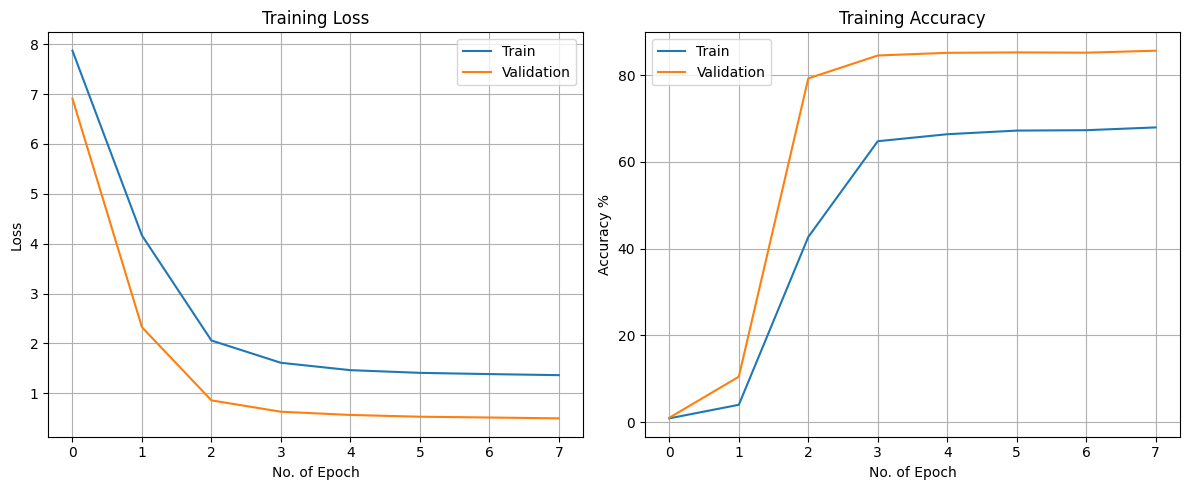

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(range(len(train_loss)), train_loss, label="Train")
axs[0].plot(range(len(val_loss)), val_loss, label="Validation")
axs[0].set_xlabel("No. of Epoch")
axs[0].set_ylabel("Loss")
axs[0].set_title("Training Loss")
axs[0].grid()
axs[0].legend()

axs[1].plot(range(len(train_accs)), train_accs, label="Train")
axs[1].plot(range(len(val_accs)), val_accs, label="Validation")
axs[1].set_xlabel("No. of Epoch")
axs[1].set_ylabel("Accuracy %")
axs[1].set_title("Training Accuracy")
axs[1].grid()
axs[1].legend()

plt.tight_layout()
plt.show()

Ora verifichiamo con test set

In [ ]:
_, test_acc = dogModel.eval_classifier(test_loader)
print(f"\nAccuracy on Testset: {round(test_acc, 2)}%")

## Custom CNN

#### CNN ORIGINALE

In [ ]:
## STRUTTURA RETE:
## 224x224 @ 3 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
## BatchNorm(32)
## ReLU
## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
## BatchNorm(32)
## ReLU
## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 64
## BatchNorm(64)
## ReLU
## 224x224 @ 64 -> MaxPooling(k= 2) -> 112x112 @ 64
## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 64
## BatchNorm(64)
## ReLU
## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 128
## BatchNorm(128)
## ReLU
## 112x112 @ 128 -> MaxPooling(k = 2) -> 56x56 @ 128
## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
## BatchNorm(128)
## ReLU
## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
## BatchNorm(128)
## ReLU
## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 256
## BatchNorm(256)
## ReLU
## 56x56 @ 256 -> MaxPooling(k = 2) -> 28x28 @ 256
## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 256
## BatchNorm(256)
## ReLU
## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 512
## BatchNorm(512)
## ReLU
## 28x28 @ 512 -> MaxPooling(k = 2) -> 14x14 @ 512
## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
## BatchNorm(512)
## ReLU
## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
## BatchNorm(512)
## ReLU
## 14x14 @ 512 -> MaxPooling(k = 2) -> 7x7 @ 512
## NN FC, 2 layer il primo con 512 canali di input ed il secondo con NUM_CLASSES canali di output
## La FC prende in input il vettore Flat.
## Il primo layer usa una Relu di attivazione con Dropout di 0.5

class DogCNN(nn.Module):
    def __init__(self, device, num_classes=NUM_CLASSES):
        super().__init__()

        self.device = device

        ## relu riutilizzabile
        self.relu = nn.ReLU()

        ## Il primo blocco applica convoluzioni per estrarre le feature più rilevanti
        ## Presuppone che le immagini siano 224 x 224 in RGB (3 canali)
        ## L'idea è quella di cominciare a dimezzare le dimensioni ma raddoppiando i canali
        ## Similmente ad una VGG (ma non uguale, anche se la differenza di fatto è il numero di canali iniziali
        ## e il numero di convoluzioni)

        ## 224x224, e si passa da 3 canali a 32 prima di cambiare le dimensioni
        ## La formula delle dimensioni è: (n - k + p + s)/s, o = [n + 2*p - k - (k-1)*(d-1)]/s + 1
        ## Con n dimensioni originali, k dimensioni kernel, p padding (default = 0) ed s stride (default = 1)
        ## Quindi per mantenere le dimensioni (ma aumentando i canali), mettiamo k = 5 (valore standard), s = 1 e p = 4, così
        ## risulta 224 - 5 (k) + 4 (p) + 1(s). Difatti p = (k - 1)/2

        ## Proviamo con kernel= 5. Per mantenere le dimensioni, padding deve essere 4
        ## Come mai 5? Un kernel più grande dovrebbe consentire di prendere più pixel
        ## alla volta ed avere informazioni sul pixel considerato.
        ## Essendo la distinzione di razze canine una task delicata come sottolineato
        ## in diversi paper (es: https://pmc.ncbi.nlm.nih.gov/articles/PMC11591900/)
        ## Potrebbe essere utile cercare di allargare questo "zoom" per scoprire i pattern delle razze
        ## visto che sono di difficile distinzione e quindi tenere un kernel piccolo potrebbe non aiutare
        ## visto che potrebbe esserci un focus su dettagli troppo piccoli o non sufficienti per la distinzione

        ## 224x224 @ 3 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=5, padding=2)
        ## BatchNorm(32)
        self.norm1 = nn.BatchNorm2d(32)
        ## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
        self.conv2 = nn.Conv2d(32, 32, kernel_size=5, padding=2)
        ## BatchNorm(32)
        self.norm2 = nn.BatchNorm2d(32)
        ## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 64
        self.conv3 = nn.Conv2d(32, 64, kernel_size = 5, padding = 2)
        ## BatchNorm(64)
        self.norm3 = nn.BatchNorm2d(64)
        ## 224x224 @ 64 -> MaxPooling(k= 2) -> 112x112 @ 64
        self.maxPool1 = nn.MaxPool2d(2)
        ## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 64
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        ## BatchNorm(64)
        self.norm4 = nn.BatchNorm2d(64)
        ## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 128
        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        ## BatchNorm(128)
        self.norm5 = nn.BatchNorm2d(128)
        ## 112x112 @ 128 -> MaxPooling(k = 2) -> 56x56 @ 128
        self.maxPool2 = nn.MaxPool2d(2)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
        self.conv6 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        ## BatchNorm(128)
        self.norm6 = nn.BatchNorm2d(128)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
        self.conv7 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        ## BatchNorm(128)
        self.norm7 = nn.BatchNorm2d(128)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 256
        self.conv8 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        ## BatchNorm(256)
        self.norm8 = nn.BatchNorm2d(256)
        ## 56x56 @ 256 -> MaxPooling(k = 2) -> 28x28 @ 256
        self.maxPool3 = nn.MaxPool2d(2)
        ## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 256
        self.conv9 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        ## BatchNorm(256)
        self.norm9 = nn.BatchNorm2d(256)
        ## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 512
        self.conv10 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        ## BatchNorm(512)
        self.norm10 = nn.BatchNorm2d(512)
        ## 28x28 @ 512 -> MaxPooling(k = 2) -> 14x14 @ 512
        self.maxPool4 = nn.MaxPool2d(2)
        ## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
        self.conv11 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        ## BatchNorm(512)
        self.norm11 = nn.BatchNorm2d(512)
        ## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
        self.conv12 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        ## BatchNorm(512)
        self.norm12 = nn.BatchNorm2d(512)
        ## 14x14 @ 512 -> MaxPooling(k = 2) -> 7x7 @ 512
        self.maxPool5 = nn.MaxPool2d(2)

        ## Classificazione con una rete sequenziale normale
        self.classifier = nn.Sequential(
            nn.Flatten(), ## Flatten per vettorizzare
            nn.Linear(512 * 7 * 7, 1024), ## 1024 di output e come input 512 canali di una 7x7 per l'ultimo MaxPool
            nn.ReLU(),
            nn.Dropout(0.5), ## Aggiungiamo dropout
            nn.Linear(1024, num_classes), ## L'output deve essere con il numero delle classi
        )

    ## Un comodo metodo per fare direttamente conv e relu assieme
    def convAndRelu(self, conv, input):
        input = conv(input)
        input = self.relu(input)
        return input

    ## Un comodo metodo per fare direttamente conv, batch e relu assieme
    def convAndBatchNormAndRelu(self, conv, norm, input):
        input = conv(input)
        input = norm(input)
        input = self.relu(input)
        return input

    def forward(self, x):
        # print(x.shape)
        ## Usiamo i layer di convoluzione e pooling
        ## 224x224 @ 3 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
        ## BatchNorm(32)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv1, self.norm1, x)
        ## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 32
        ## BatchNorm(32)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv2, self.norm2, x)
        ## 224x224 @ 32 -> Conv2d(k=5, p=2, s=1) -> 224x224 @ 64
        ## BatchNorm(64)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv3, self.norm3, x)
        ## 224x224 @ 64 -> MaxPooling(k= 2) -> 112x112 @ 64
        x = self.maxPool1(x)
        ## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 64
        ## BatchNorm(64)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv4, self.norm4, x)
        ## 112x112 @ 64 -> Conv2d(k=3, p=1, s=1) -> 112x112 @ 128
        ## BatchNorm(128)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv5, self.norm5, x)
        ## 112x112 @ 128 -> MaxPooling(k = 2) -> 56x56 @ 128
        x = self.maxPool2(x)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
        ## BatchNorm(128)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv6, self.norm6, x)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 128
        ## BatchNorm(128)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv7, self.norm7, x)
        ## 56x56 @ 128 -> Conv2d(k=3, p=1, s=1) -> 56x56 @ 256
        ## BatchNorm(256)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv8, self.norm8, x)
        ## 56x56 @ 256 -> MaxPooling(k = 2) -> 28x28 @ 256
        x = self.maxPool3(x)
        ## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 256
        ## BatchNorm(256)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv9, self.norm9, x)
        ## 28x28 @ 256 -> Conv2d(k=3, p=1, s=1) -> 28x28 @ 512
        ## BatchNorm(512)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv10, self.norm10, x)
        ## 28x28 @ 512 -> MaxPooling(k = 2) -> 14x14 @ 512
        x = self.maxPool4(x)
        ## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
        ## BatchNorm(512)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv11, self.norm11, x)
        ## 14x14 @ 512 -> Conv2d(k=3, p=1, s=1) -> 14x14 @ 512
        ## BatchNorm(512)
        ## ReLU
        x = self.convAndBatchNormAndRelu(self.conv12, self.norm12, x)
        ## 14x14 @ 512 -> MaxPooling(k = 2) -> 7x7 @ 512
        x = self.maxPool5(x)
        ## NN standard
        x = self.classifier(x)
        return x

    def train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
        epochs,
        device,
        path_pesi = ""
    ):
        best_val_loss = float("inf")

        for ep in range(epochs):

            model.train()
            running_loss = 0.0
            correct = 0
            total = 0

            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                logits = model(images)
                loss = criterion(logits, labels)

                loss.backward()

                optimizer.step()

                running_loss += loss.item()
                preds = logits.argmax(dim=1)

                correct += (preds == labels).sum().item()
                total += labels.size(0)

            train_loss = running_loss / len(train_loader)
            train_acc = 100 * correct / total

            print(f"EPOCH: {ep+1}/{epochs}, Train Loss: {train_loss:.3f}, Train Acc: {train_acc:.3f}%")

            model.eval()
            val_loss = 0.0
            val_correct = 0
            val_total = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(device)
                    labels = labels.to(device)

                    logits = model(images)
                    loss = criterion(logits, labels)

                    val_loss += loss.item()
                    preds = logits.argmax(dim=1)

                    val_correct += (preds == labels).sum().item()
                    val_total += labels.size(0)

            val_loss /= len(val_loader)
            val_acc = 100 * val_correct / val_total

            print(f"Val Loss: {val_loss:.3f} | Val Acc: {val_acc:.2f}%")

            if path_pesi != "" and val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(model.state_dict(), path_pesi)

        return train_loss, val_loss, train_acc, val_acc


    def eval_classifier(self, dataloader, criterion):
        self.eval()

        val_loss = 0
        val_accs = 0
        total = 0

        for it, (images, labels) in enumerate(tqdm(dataloader, desc="Val")):

            with torch.no_grad():
                images = images.to(self.device)
                labels = labels.to(self.device)

                # Forward pass
                logits = self.forward(images)

                loss = criterion(logits, labels)
                val_loss += loss.item()

                predictions = torch.max(logits, 1).indices
                val_accs += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
                total += len(labels)

        return val_loss/len(dataloader), val_accs/total*100


#### TRY: SMALL CNN

In [ ]:
AVG_POOL_FC = 1

class smallCustomCNN(nn.Module):

  def __init__(self, device, num_classes = NUM_CLASSES):
    super().__init__()

    self.device = device

    ## Siamo sempre in una 224x224 di input con 3 canali
    ## Proviamo prima senza BatchNorm
    self.relu = nn.ReLU()

    ## 3 -> 64 canali
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
    ## 224x224 -> 112x112
    self.maxPool1 = nn.MaxPool2d(2)

    ## 64 -> 128 canali
    self.conv2 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
    ## 112x112 -> 56x56
    self.maxPool2 = nn.MaxPool2d(2)

    ## 128 -> 256 canali
    self.conv3 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
    ## 56x56 -> 28x28
    self.maxPool3 = nn.MaxPool2d(2)

    self.dense = nn.Sequential(
        nn.AdaptiveAvgPool2d((AVG_POOL_FC, AVG_POOL_FC)),
        nn.Flatten(),
        nn.Linear(256 * AVG_POOL_FC * AVG_POOL_FC, num_classes)
    )

  ## Un comodo metodo per fare direttamente conv e relu assieme
  def convAndRelu(self, conv, input):
      input = conv(input)
      input = self.relu(input)
      return input

  ## Un comodo metodo per fare direttamente conv, relu e pool assieme
  def convAndReluAndPool(self, conv, pool, input):
      input = conv(input)
      input = self.relu(input)
      input = pool(input)
      return input

  def forward(self, input):
    input = self.convAndReluAndPool(self.conv1, self.maxPool1, input)
    input = self.convAndReluAndPool(self.conv2, self.maxPool2, input)
    input = self.convAndReluAndPool(self.conv3, self.maxPool3, input)
    input = self.dense(input)
    return input

  def train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
        epochs,
        device,
        path_pesi = ""
    ):
      best_val_loss = float("inf")

      for ep in range(epochs):

          model.train()
          running_loss = 0.0
          correct = 0
          total = 0

          for images, labels in train_loader:
              images = images.to(device)
              labels = labels.to(device)

              optimizer.zero_grad()

              logits = model(images)
              loss = criterion(logits, labels)

              loss.backward()

              optimizer.step()

              running_loss += loss.item()
              preds = logits.argmax(dim=1)

              correct += (preds == labels).sum().item()
              total += labels.size(0)

          train_loss = running_loss / len(train_loader)
          train_acc = 100 * correct / total

          print(f"EPOCH: {ep+1}/{epochs}, Train Loss: {train_loss:.3f}, Train Acc: {train_acc:.3f}%")

          model.eval()
          val_loss = 0.0
          val_correct = 0
          val_total = 0

          with torch.no_grad():
              for images, labels in val_loader:
                  images = images.to(device)
                  labels = labels.to(device)

                  logits = model(images)
                  loss = criterion(logits, labels)

                  val_loss += loss.item()
                  preds = logits.argmax(dim=1)

                  val_correct += (preds == labels).sum().item()
                  val_total += labels.size(0)

          val_loss /= len(val_loader)
          val_acc = 100 * val_correct / val_total

          print(f"Val Loss: {val_loss:.3f} | Val Acc: {val_acc:.2f}%")

          if path_pesi != "" and val_loss < best_val_loss:
              best_val_loss = val_loss
              torch.save(model.state_dict(), path_pesi)

      return train_loss, val_loss, train_acc, val_acc


  def eval_classifier(self, dataloader, criterion):
      self.eval()

      val_loss = 0
      val_accs = 0
      total = 0

      for it, (images, labels) in enumerate(tqdm(dataloader, desc="Val")):

          with torch.no_grad():
              images = images.to(self.device)
              labels = labels.to(self.device)

              # Forward pass
              logits = self.forward(images)

              loss = criterion(logits, labels)
              val_loss += loss.item()

              predictions = torch.max(logits, 1).indices
              val_accs += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
              total += len(labels)

      return val_loss/len(dataloader), val_accs/total*100

#### MEDIUM CNN (SMALL CNN MIGLIORATA)
Miglioramenti:  
Due convolution per block
Il primo blocco usa kernel 5x5 anziché 3x3

In [ ]:
AVG_POOL_FC = 1

class mediumCustomCNN(nn.Module):

  def __init__(self, device, num_classes = NUM_CLASSES):
    super().__init__()

    self.device = device

    ## Siamo sempre in una 224x224 di input con 3 canali
    ## Proviamo prima senza BatchNorm
    self.relu = nn.ReLU()

    ## 3 -> 64 canali
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=5, padding=2)
    self.conv1b = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5, padding=2)
    ## 224x224 -> 112x112
    self.maxPool1 = nn.MaxPool2d(2)

    ## 64 -> 128 canali
    self.conv2 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
    self.conv2b = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
    ## 112x112 -> 56x56
    self.maxPool2 = nn.MaxPool2d(2)

    ## 128 -> 256 canali
    self.conv3 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
    self.conv3b = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
    ## 56x56 -> 28x28
    self.maxPool3 = nn.MaxPool2d(2)

    self.dense = nn.Sequential(
        nn.AdaptiveAvgPool2d((AVG_POOL_FC, AVG_POOL_FC)),
        nn.Flatten(),
        nn.Linear(256 * AVG_POOL_FC * AVG_POOL_FC, num_classes)
    )

  ## Un comodo metodo per fare direttamente conv e relu assieme
  def convAndRelu(self, conv, input):
      input = conv(input)
      input = self.relu(input)
      return input

  ## Un comodo metodo per fare direttamente conv, relu e pool assieme
  def convAndReluAndPool(self, conv, pool, input):
      input = conv(input)
      input = self.relu(input)
      input = pool(input)
      return input

  def forward(self, input):
    ## Aggiunta: il secondo conv per ogni blocco. I conv non "b" aumentano i canali
    input = self.convAndRelu(self.conv1, input)
    input = self.convAndReluAndPool(self.conv1b, self.maxPool1, input) ## Notare che si usano i b per anche pooling
    input = self.convAndRelu(self.conv2, input)
    input = self.convAndReluAndPool(self.conv2b, self.maxPool2, input)
    input = self.convAndRelu(self.conv3, input)
    input = self.convAndReluAndPool(self.conv3b, self.maxPool3, input)
    input = self.dense(input)
    return input

  def train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
        epochs,
        device,
        path_pesi = ""
    ):
      best_val_loss = float("inf")

      for ep in range(epochs):

          model.train()
          running_loss = 0.0
          correct = 0
          total = 0

          for images, labels in train_loader:
              images = images.to(device)
              labels = labels.to(device)

              optimizer.zero_grad()

              logits = model(images)
              loss = criterion(logits, labels)

              loss.backward()

              optimizer.step()

              running_loss += loss.item()
              preds = logits.argmax(dim=1)

              correct += (preds == labels).sum().item()
              total += labels.size(0)

          train_loss = running_loss / len(train_loader)
          train_acc = 100 * correct / total

          print(f"EPOCH: {ep+1}/{epochs}, Train Loss: {train_loss:.3f}, Train Acc: {train_acc:.3f}%")

          model.eval()
          val_loss = 0.0
          val_correct = 0
          val_total = 0

          with torch.no_grad():
              for images, labels in val_loader:
                  images = images.to(device)
                  labels = labels.to(device)

                  logits = model(images)
                  loss = criterion(logits, labels)

                  val_loss += loss.item()
                  preds = logits.argmax(dim=1)

                  val_correct += (preds == labels).sum().item()
                  val_total += labels.size(0)

          val_loss /= len(val_loader)
          val_acc = 100 * val_correct / val_total

          print(f"Val Loss: {val_loss:.3f} | Val Acc: {val_acc:.2f}%")

          if path_pesi != "" and val_loss < best_val_loss:
              best_val_loss = val_loss
              torch.save(model.state_dict(), path_pesi)

      return train_loss, val_loss, train_acc, val_acc


  def eval_classifier(self, dataloader, criterion):
      self.eval()

      val_loss = 0
      val_accs = 0
      total = 0

      for it, (images, labels) in enumerate(tqdm(dataloader, desc="Val")):

          with torch.no_grad():
              images = images.to(self.device)
              labels = labels.to(self.device)

              # Forward pass
              logits = self.forward(images)

              loss = criterion(logits, labels)
              val_loss += loss.item()

              predictions = torch.max(logits, 1).indices
              val_accs += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
              total += len(labels)

      return val_loss/len(dataloader), val_accs/total*100

#### BOOSTED MEDIUM CNN
Medium CNN con BathcNorm dopo ogni Conv+Relu

In [ ]:
AVG_POOL_FC = 1

class boostedMediumCustomCNN(nn.Module):

  def __init__(self, device, num_classes = NUM_CLASSES):
    super().__init__()

    self.device = device

    ## Siamo sempre in una 224x224 di input con 3 canali
    ## Proviamo prima senza BatchNorm
    self.relu = nn.ReLU()

    ## 3 -> 64 canali
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=5, padding=2)
    self.norm1 = nn.BatchNorm2d(64)
    self.conv1b = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5, padding=2)
    self.norm1b = nn.BatchNorm2d(64)
    ## 224x224 -> 112x112
    self.maxPool1 = nn.MaxPool2d(2)

    ## 64 -> 128 canali
    self.conv2 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
    self.norm2 = nn.BatchNorm2d(128)
    self.conv2b = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
    self.norm2b = nn.BatchNorm2d(128)
    ## 112x112 -> 56x56
    self.maxPool2 = nn.MaxPool2d(2)

    ## 128 -> 256 canali
    self.conv3 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
    self.norm3 = nn.BatchNorm2d(256)
    self.conv3b = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
    self.norm3b = nn.BatchNorm2d(256)
    ## 56x56 -> 28x28
    self.maxPool3 = nn.MaxPool2d(2)

    self.dense = nn.Sequential(
        nn.AdaptiveAvgPool2d((AVG_POOL_FC, AVG_POOL_FC)),
        nn.Flatten(),
        nn.Linear(256 * AVG_POOL_FC * AVG_POOL_FC, num_classes)
    )

  ## Un comodo metodo per fare direttamente conv e relu assieme
  def convAndRelu(self, conv, input):
    input = conv(input)
    input = self.relu(input)
    return input

  ## Un comodo metodo per fare direttamente conv, relu e pool assieme
  def convAndReluAndPool(self, conv, pool, input):
    input = conv(input)
    input = self.relu(input)
    input = pool(input)
    return input

  def convAndNormAndReluAndPool(self, conv, norm, pool, input):
    input = conv(input)
    input = norm(input)
    input = self.relu(input)
    input = pool(input)
    return input

  def convAndNormAndRelu(self, conv, norm, input):
    input = conv(input)
    input = norm(input)
    input = self.relu(input)
    return input

  def forward(self, input):
    ## Aggiunta: ora usiamo Norm dopo ogni conv e prima di ogni ReLU per migliorare il gradient flow
    input = self.convAndNormAndRelu(self.conv1, self.norm1, input)
    input = self.convAndNormAndReluAndPool(self.conv1b, self.norm1b, self.maxPool1, input)
    input = self.convAndNormAndRelu(self.conv2, self.norm2, input)
    input = self.convAndNormAndReluAndPool(self.conv2b, self.norm2b, self.maxPool2, input)
    input = self.convAndNormAndRelu(self.conv3, self.norm3, input)
    input = self.convAndNormAndReluAndPool(self.conv3b, self.norm3b, self.maxPool3, input)
    input = self.dense(input)
    return input

  def train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
        epochs,
        device,
        path_pesi = ""
    ):
      best_val_loss = float("inf")

      for ep in range(epochs):

          model.train()
          running_loss = 0.0
          correct = 0
          total = 0

          for images, labels in train_loader:
              images = images.to(device)
              labels = labels.to(device)

              optimizer.zero_grad()

              logits = model(images)
              loss = criterion(logits, labels)

              loss.backward()

              optimizer.step()

              running_loss += loss.item()
              preds = logits.argmax(dim=1)

              correct += (preds == labels).sum().item()
              total += labels.size(0)

          train_loss = running_loss / len(train_loader)
          train_acc = 100 * correct / total

          print(f"EPOCH: {ep+1}/{epochs}, Train Loss: {train_loss:.3f}, Train Acc: {train_acc:.3f}%")

          model.eval()
          val_loss = 0.0
          val_correct = 0
          val_total = 0

          with torch.no_grad():
              for images, labels in val_loader:
                  images = images.to(device)
                  labels = labels.to(device)

                  logits = model(images)
                  loss = criterion(logits, labels)

                  val_loss += loss.item()
                  preds = logits.argmax(dim=1)

                  val_correct += (preds == labels).sum().item()
                  val_total += labels.size(0)

          val_loss /= len(val_loader)
          val_acc = 100 * val_correct / val_total

          print(f"Val Loss: {val_loss:.3f} | Val Acc: {val_acc:.2f}%")

          if path_pesi != "" and val_loss < best_val_loss:
              best_val_loss = val_loss
              torch.save(model.state_dict(), path_pesi)

      return train_loss, val_loss, train_acc, val_acc


  def eval_classifier(self, dataloader, criterion):
      self.eval()

      val_loss = 0
      val_accs = 0
      total = 0

      for it, (images, labels) in enumerate(tqdm(dataloader, desc="Val")):

          with torch.no_grad():
              images = images.to(self.device)
              labels = labels.to(self.device)

              # Forward pass
              logits = self.forward(images)

              loss = criterion(logits, labels)
              val_loss += loss.item()

              predictions = torch.max(logits, 1).indices
              val_accs += (predictions.detach().cpu() == labels.detach().cpu()).sum().item()
              total += len(labels)

      return val_loss/len(dataloader), val_accs/total*100

  def extract_embedding(self, input):
    input = self.convAndNormAndRelu(self.conv1, self.norm1, input)
    input = self.convAndNormAndReluAndPool(self.conv1b, self.norm1b, self.maxPool1, input)
    input = self.convAndNormAndRelu(self.conv2, self.norm2, input)
    input = self.convAndNormAndReluAndPool(self.conv2b, self.norm2b, self.maxPool2, input)
    input = self.convAndNormAndRelu(self.conv3, self.norm3, input)
    input = self.convAndNormAndReluAndPool(self.conv3b, self.norm3b, self.maxPool3, input)
    return input


### Creazione e Training Custom CNN

In [ ]:
EPOCHS = 20

lr = 1e-3
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print("Device", device)

customDogModel = DogCNN(device).to(device)
# customDogModel = smallCustomCNN(device).to(device)
# customDogModel = mediumCustomCNN(device).to(device)
# customDogModel = boostedMediumCustomCNN(device).to(device)

optimizer = torch.optim.Adam(customDogModel.parameters(), lr=lr)
cnn_criterion = nn.CrossEntropyLoss()

PATH_PESI = "/content/drive/PesiCustomCNN" ## CAMBIARE IL PATH ALL'OCCORRENZA
## Usare il file desiderato commentando
FILE_MODELLO = "original_model.pt"   ## CNN "originale"
# FILE_MODELLO = "small_model.pt"  ## CNN piccola
# FILE_MODELLO = "medium_model.pt"   ## CNN media
# FILE_MODELLO = "norm_medium_model.pt"   ## CNN media con Norm
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, FILE_MODELLO)


Device cuda


In [ ]:
## In caso i pesi siano già presenti:
customDogModel.load_state_dict(torch.load(PATH_PESI_LOAD)) ## <- Se si sta usando T4
# customDogModel.load_state_dict(torch.load(PATH_PESI_LOAD, map_location=torch.device('cpu')))
customDogModel.to(device)
customDogModel.eval()


boostedMediumCustomCNN(
  (relu): ReLU()
  (conv1): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv1b): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (norm1b): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxPool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2b): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (norm2b): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxPool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (norm3): BatchNorm2d

CNN MEDIA BOOSTED

In [ ]:
customDogModel.train_model(
    train_loader,
    val_loader,
    optimizer,
    cnn_criterion,
    EPOCHS,
    device,
    PATH_PESI_LOAD  ## da decommentare se si vogliono salvare i pesi (e cancellare la stringa vuota dopo)
    # ""
)


EPOCH: 1/2, Train Loss: 3.465, Train Acc: 18.201%
Val Loss: 3.458 | Val Acc: 17.49%
EPOCH: 2/2, Train Loss: 3.429, Train Acc: 18.999%
Val Loss: 3.316 | Val Acc: 20.38%


(3.4292014489131692, 3.316498317718506, 18.999028182701654, 20.375769355361193)

### TRAIN SU TUTTE LE CNN PER SALVARNE I MODELLI, DA ESEGUIRE PER ALLENARE TUTTE LE CNN CUSTOM

CNN PICCOLA

In [ ]:
customDogModel = smallCustomCNN(device).to(device)

FILE_MODELLO = "small_model.pt"  ## CNN piccola
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, FILE_MODELLO)

optimizer = torch.optim.Adam(customDogModel.parameters(), lr=lr)
cnn_criterion = nn.CrossEntropyLoss()

customDogModel.train_model(
    train_loader,
    val_loader,
    optimizer,
    cnn_criterion,
    EPOCHS,
    device,
    PATH_PESI_LOAD
)

EPOCH: 1/20, Train Loss: 4.733, Train Acc: 1.555%
Val Loss: 4.661 | Val Acc: 2.79%
EPOCH: 2/20, Train Loss: 4.633, Train Acc: 2.499%
Val Loss: 4.615 | Val Acc: 2.62%
EPOCH: 3/20, Train Loss: 4.584, Train Acc: 2.888%
Val Loss: 4.543 | Val Acc: 3.01%
EPOCH: 4/20, Train Loss: 4.540, Train Acc: 3.568%
Val Loss: 4.531 | Val Acc: 3.56%
EPOCH: 5/20, Train Loss: 4.508, Train Acc: 4.220%
Val Loss: 4.504 | Val Acc: 4.11%
EPOCH: 6/20, Train Loss: 4.479, Train Acc: 4.144%
Val Loss: 4.474 | Val Acc: 4.28%
EPOCH: 7/20, Train Loss: 4.463, Train Acc: 4.706%
Val Loss: 4.446 | Val Acc: 5.57%
EPOCH: 8/20, Train Loss: 4.430, Train Acc: 5.165%
Val Loss: 4.443 | Val Acc: 5.18%
EPOCH: 9/20, Train Loss: 4.413, Train Acc: 5.171%
Val Loss: 4.405 | Val Acc: 6.12%
EPOCH: 10/20, Train Loss: 4.380, Train Acc: 5.685%
Val Loss: 4.367 | Val Acc: 6.45%
EPOCH: 11/20, Train Loss: 4.332, Train Acc: 6.164%
Val Loss: 4.346 | Val Acc: 6.51%
EPOCH: 12/20, Train Loss: 4.296, Train Acc: 6.615%
Val Loss: 4.282 | Val Acc: 7.00%
E

(3.9968623228832683, 4.060316858291626, 11.23837290018048, 10.268869452542923)

CNN MEDIA

In [ ]:
customDogModel = mediumCustomCNN(device).to(device)

FILE_MODELLO = "medium_model.pt"   ## CNN media
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, FILE_MODELLO)

optimizer = torch.optim.Adam(customDogModel.parameters(), lr=lr)
cnn_criterion = nn.CrossEntropyLoss()

customDogModel.train_model(
    train_loader,
    val_loader,
    optimizer,
    cnn_criterion,
    EPOCHS,
    device,
    PATH_PESI_LOAD
)

EPOCH: 1/20, Train Loss: 4.766, Train Acc: 1.222%
Val Loss: 4.725 | Val Acc: 1.85%
EPOCH: 2/20, Train Loss: 4.674, Train Acc: 2.194%
Val Loss: 4.646 | Val Acc: 2.33%
EPOCH: 3/20, Train Loss: 4.631, Train Acc: 2.471%
Val Loss: 4.624 | Val Acc: 2.20%
EPOCH: 4/20, Train Loss: 4.606, Train Acc: 2.686%
Val Loss: 4.597 | Val Acc: 2.92%
EPOCH: 5/20, Train Loss: 4.560, Train Acc: 2.922%
Val Loss: 4.511 | Val Acc: 3.69%
EPOCH: 6/20, Train Loss: 4.518, Train Acc: 3.457%
Val Loss: 4.455 | Val Acc: 3.89%
EPOCH: 7/20, Train Loss: 4.469, Train Acc: 4.304%
Val Loss: 4.416 | Val Acc: 4.11%
EPOCH: 8/20, Train Loss: 4.413, Train Acc: 4.561%
Val Loss: 4.341 | Val Acc: 5.64%
EPOCH: 9/20, Train Loss: 4.345, Train Acc: 5.532%
Val Loss: 4.294 | Val Acc: 5.51%
EPOCH: 10/20, Train Loss: 4.294, Train Acc: 5.900%
Val Loss: 4.166 | Val Acc: 7.16%
EPOCH: 11/20, Train Loss: 4.218, Train Acc: 6.775%
Val Loss: 4.105 | Val Acc: 8.33%
EPOCH: 12/20, Train Loss: 4.163, Train Acc: 7.726%
Val Loss: 4.025 | Val Acc: 8.94%
E

(3.7413129848716533,
 3.7618259143829347,
 13.980285991947799,
 14.318108195659216)

CNN ORIGINALE

In [ ]:
customDogModel = DogCNN(device).to(device)

FILE_MODELLO = "original_model.pt"  ## CNN originale
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, FILE_MODELLO)

optimizer = torch.optim.Adam(customDogModel.parameters(), lr=lr)
cnn_criterion = nn.CrossEntropyLoss()

customDogModel.train_model(
    train_loader,
    val_loader,
    optimizer,
    cnn_criterion,
    EPOCHS,
    device,
    PATH_PESI_LOAD
)

EPOCH: 1/20, Train Loss: 6.020, Train Acc: 0.757%
Val Loss: 4.788 | Val Acc: 1.07%
EPOCH: 2/20, Train Loss: 4.787, Train Acc: 1.041%
Val Loss: 4.787 | Val Acc: 0.91%
EPOCH: 3/20, Train Loss: 4.780, Train Acc: 1.097%
Val Loss: 4.765 | Val Acc: 1.55%
EPOCH: 4/20, Train Loss: 4.765, Train Acc: 1.236%
Val Loss: 4.737 | Val Acc: 1.39%
EPOCH: 5/20, Train Loss: 4.752, Train Acc: 1.243%
Val Loss: 4.730 | Val Acc: 1.49%
EPOCH: 6/20, Train Loss: 4.743, Train Acc: 1.256%
Val Loss: 4.716 | Val Acc: 1.43%
EPOCH: 7/20, Train Loss: 4.743, Train Acc: 1.527%
Val Loss: 4.721 | Val Acc: 1.59%
EPOCH: 8/20, Train Loss: 4.735, Train Acc: 1.444%
Val Loss: 4.701 | Val Acc: 1.72%
EPOCH: 9/20, Train Loss: 4.725, Train Acc: 1.694%
Val Loss: 4.693 | Val Acc: 1.33%
EPOCH: 10/20, Train Loss: 4.731, Train Acc: 1.722%
Val Loss: 4.705 | Val Acc: 1.65%
EPOCH: 11/20, Train Loss: 4.719, Train Acc: 1.819%
Val Loss: 4.674 | Val Acc: 1.78%
EPOCH: 12/20, Train Loss: 4.718, Train Acc: 1.735%
Val Loss: 4.670 | Val Acc: 1.65%
E

In [ ]:
_, test_acc = customDogModel.eval_classifier(test_loader, cnn_criterion)
print(f"\nAccuracy on Testset: {round(test_acc, 2)}%")

Val: 100%|██████████| 25/25 [27:34<00:00, 66.18s/it]


Accuracy on Testset: 0.65%


# ANALISI RISULTATI

Alcuni dati, alla 20esima epoca:
> CNN ORIGINALE:  
Train Loss: 4.372, Train Acc: 3.873%  
Val Loss: 4.222 | Val Acc: 5.77%  
(4.372324053165132, 4.221890926361084, 3.8733860891295295, 5.766115970197603)

> SMALL CNN:   
Train Loss: 3.949, Train Acc: 11.849%  
Val Loss: 3.996 | Val Acc: 11.11%  
(3.948533948543852, 3.9955227851867674, 11.849229487713453, 11.11111111111111)

> MEDIUM CNN:  
Train Loss: 3.728, Train Acc: 14.189%  
Val Loss: 3.614 | Val Acc: 15.06%  
(3.728051820687488, 3.6143331146240234, 14.188532555879494, 15.063168124392615)

> NORM MEDIUM CNN:  
Train Loss: 3.429, Train Acc: 18.999%  
Val Loss: 3.316 | Val Acc: 20.38%  
(3.4292014489131692, 3.316498317718506, 18.999028182701654, 20.375769355361193)

Considerazioni:  
L'obbiettivo iniziale di creare una rete simil VGG nella speranza di ottenere buoni risultati si è dimostrata fallimentare, ottenendo un'accuracy di appena 5.8% ed una loss di 4.2 sul validation set.  
  
Optando invece per una CNN più piccola si sono ottenuti risultati migliori arrivando a 11% di accuracy e circa 4 di loss sul validaiton set.  
Le modifiche con la CNN piccola rispetto alla rete originale includono:  
- Uso di 3 blocchi di convoluzione anziché 5
- Uso di 1 layer Full Connected anziché 2
- Canali in input della Full Connected da 512 con input 7x7 a 256 con input 28x28
- Uso di Adaptative Avg Pool
- Rimozione di Batch Normalization  
  
In più, il training sulla CNN originale portava spesso ad un Out of Memory: questo è dovuto alle sue dimensioni. Parliamo infatti di circa 33 milioni di parametri. La CNN "Small" invece ne ha solamente 402 mila. Questo implica meno problemi di memoria ed un allenamento anche più veloce.
  
Per cercare di migliorare la "small CNN", viene aggiunto un ulteriore blocco di convoluzione prima di ciascun Max Pooling. L'accuracy arriva al 15% sul validation set. La "Medium CNN" invece ha circa 1 milione e 24 mila parametri.  
  
Infine, la "Boosted Medium CNN" usa Batch Normalization con la "Medium CNN" e questo consente di migliorare a 20.4% accuracy sul validation set. L'aggiunta di Batch Normalization porta un'aggiunta di 1792 parametri, un numero insignificante rispetto all'oltre milione già presente. Ma ha comunque dimostrato di essere un ottimo miglioramento, aumentando l'accuracy di circa il 5%.

# Somiglianza Embedding

### COSINE SIMILARITY: CONFRONTO TRA EMBEDDING

Il prossimo passo è quello di usare una delle reti precedenti per confrontare embedding e trovare la foto più simile in tutto il dataset.  
Essendo la rete con TransferLearning la più soddisfacente in termini di accuracy e loss, si è deciso di usare quella.  
I passi da fare sono:
- Trasformare tutte le immagini del dataset nelle versioni embedded
- Possibilità di passare una foto ed ottenerne l'embedding
- Controllare tra gli embedding presenti quale sia quello con la più alta similarità. Lo strumento di misura adottato è la Cosine Similarity che la libreria Pytorch mette a disposizione



Per creare gli embedding delle foto, usiamo extract_embedding della rete con Transfer Learning dove vengono usati i layer della ResNet50

In [ ]:
## Creiamo un DataLoader col dataset originale
loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=False
)

In [ ]:
## Ora ricreiamo il modello
## Se è già stato fatto, si può saltare questa cella. Si trova qui solo per non tornare su...
repo_id = "djhua0103/dog-breed-resnet50"

ckpt_path = hf_hub_download(repo_id, "resnet50_dog_best.pth")
json_path = hf_hub_download(repo_id, "id2breed.json")

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

dogModel = TransferDogBreedsModel(device, ckpt_path).to(device)

PATH_PESI = "/content/drive/PesiFC_TL" ## CAMBIARE IL PATH ALL'OCCORRENZA
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, "best_TL_fc.pt")

# dogModel.load_state_dict(torch.load(PATH_PESI_LOAD)) ## <- Se si sta usando T4
dogModel.backbone.fc.load_state_dict(torch.load(PATH_PESI_LOAD, map_location=torch.device('cpu')))
dogModel.to(device)
dogModel.eval() ## Importante metterlo in eval

PATH_EMBEDDING = "/content/drive/embeddings_cani.pt" ## CAMBIARE IL PATH ALL'OCCORRENZA


In [ ]:
## Se si vuole caricare:
db = torch.load(PATH_EMBEDDING)

embeddings = db["embeddings"]
labels = db["labels"]
paths = db["paths"]
classes = db["classes"]

## Normalizzazione per sicurezza
embeddings = F.normalize(embeddings, dim=1)

## Altrimenti, cella qua sotto

In [ ]:
## Creazione dell'embedding
## Se invece è già stato creato, si troverà su un path

embeddings = []
labels = []
paths = []

with torch.no_grad():
    for batch_idx, (imgs, lbls) in enumerate(loader):
        imgs = imgs.to(device)

        emb = dogModel.extract_embedding(imgs)
        emb = F.normalize(emb, dim=1)

        embeddings.append(emb.cpu())
        labels.extend(lbls.tolist())

        start = batch_idx * loader.batch_size
        end = start + len(lbls)

        for i in range(start, end):
            paths.append(dataset.samples[i][0])

embeddings = torch.cat(embeddings)  # (N, 2048)
# torch.save(embeddings, PATH_EMBEDDING)

# embeddings = torch.cat(embeddings)

torch.save(
    {
        "embeddings": embeddings,
        "labels": labels,
        "paths": paths,
        "classes": dataset.classes
    },
    PATH_EMBEDDING
)


Uso effettivo: confronto di embedding

In [ ]:
## Metodo per ottenere l'embedding di una foto
def image_to_embedding(img_path, model, transform, device):
    img = Image.open(img_path).convert("RGB")
    img = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        emb = model.extract_embedding(img)
        emb = F.normalize(emb, dim=1)

    return emb


## Metodo per trovare la foto più simile
def find_most_similar(query_emb, embeddings, top_k=3):
    sims = query_emb @ embeddings.T
    top_scores, top_indices = torch.topk(sims, k=top_k, dim=1)

    indices = top_indices[0].tolist()
    scores = top_scores[0].tolist()

    return indices, scores

## Metodo per comparare le due foto, originale vs embeddata
def show_comparison(query_path, matched_path, label, score):
    query_img = Image.open(query_path).convert("RGB")
    matched_img = Image.open(matched_path).convert("RGB")

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(query_img)
    plt.title("Immagine Originale")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(matched_img)
    plt.title(f"Match: {label}\nCosine: {score:.3f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## Metodo per comparare query con top-k matches
def show_comparison_with_topk(query_path, matched_paths, matched_labels, scores,
                               predicted_class, confidence, top_k=3):
    query_img = Image.open(query_path).convert("RGB")

    # Create figure with 1 row for query + prediction, and 1 row for top-k matches
    fig = plt.figure(figsize=(15, 8))

    # Top row: Query image and prediction info
    ax1 = plt.subplot(2, top_k + 1, 1)
    ax1.imshow(query_img)
    ax1.set_title("Foto Originale", fontsize=12, fontweight='bold')
    ax1.axis("off")

    # Prediction info (text only)
    ax2 = plt.subplot(2, top_k + 1, 2)
    ax2.axis("off")
    pred_text = f"Predizione:\n\n{predicted_class}\n\nConfidence: {confidence:.3f}"
    ax2.text(0.5, 0.5, pred_text, fontsize=11, ha='center', va='center',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

    # Bottom row: Top-k similar images
    for i in range(top_k):
        ax = plt.subplot(2, top_k + 1, top_k + 2 + i)
        matched_img = Image.open(matched_paths[i]).convert("RGB")
        ax.imshow(matched_img)
        ax.set_title(f"#{i+1}: {matched_labels[i]}\nCosine Similarity: {scores[i]:.3f}",
                     fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Metodo per predire la classe di un'immagine
def predict_class(img_path, model, transform, device, classes):
    img = Image.open(img_path).convert("RGB")
    img = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img)
        probs = F.softmax(output, dim=1)

        confidence, pred_idx = torch.max(probs, dim=1)
        predicted_class = classes[pred_idx.item()]

    return predicted_class, confidence.item()

Creazione array coi cani da confrontare

In [ ]:
## Ora effettivamente convertiamo
PATH_CANI_DA_TESTATE = "/content/drive/MyDrive/737664 - Progetto Deep & Reti/737664 - DL & ARN Progetto/CaniDaTestare" ## CAMBIARE IL PATH ALL'OCCORRENZA
caniDaTestare = [
    ## Praticamente itera su tutte le foto che trova nella cartella e le salva in questo array
    os.path.join(PATH_CANI_DA_TESTATE, f)
    for f in os.listdir(PATH_CANI_DA_TESTATE)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

Ora si cercano tutti

In [ ]:
for cane in caniDaTestare:
    # Get embedding
    caneEmb = image_to_embedding(cane, dogModel, val_transform, device)

    # Get single prediction from model
    predicted_class, confidence = predict_class(
        cane, dogModel, val_transform, device, classes
    )

    # Find top-3 similar images
    indices, scores = find_most_similar(caneEmb, embeddings, top_k=3)
    matched_paths = [paths[idx] for idx in indices]
    matched_labels = [classes[labels[idx]] for idx in indices]

    # Display
    show_comparison_with_topk(cane, matched_paths, matched_labels, scores,
                              predicted_class, confidence, top_k=3)

## Confronto con CNN Custom

Si vuole ora vedere invece il confronto con una CNN custom. Per l'occasione è staat usata la CNN "Medium Boosteed"

In [ ]:
## Settaggio della rete, stesse celle sopra
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

customDogModel = boostedMediumCustomCNN(device).to(device)


PATH_PESI = "/content/drive/PesiCustomCNN" ## CAMBIARE IL PATH ALL'OCCORRENZA
## Usare il file desiderato commentando
FILE_MODELLO = "norm_medium_model.pt"   ## CNN media con Norm
PATH_PESI_LOAD = path = os.path.join(PATH_PESI, FILE_MODELLO)


In [ ]:
## Caricamento pesi
customDogModel.load_state_dict(torch.load(PATH_PESI_LOAD)) ## <- Se si sta usando T4
# customDogModel.load_state_dict(torch.load(PATH_PESI_LOAD, map_location=torch.device('cpu')))
customDogModel.to(device)
customDogModel.eval()

## NOTA: QUESTO FILE NON è PRESENTE NELLA CARTELLA FORNITA PER MOTIVI SPIEGATI NELLA RELAZIONE
PATH_EMBEDDING = "/content/drive/embeddings_cani_custom.pt" ## CAMBIARE IL PATH ALL'OCCORRENZA

In [ ]:
## Se si vuole caricare embedding:
db = torch.load(PATH_EMBEDDING)

embeddings = db["embeddings"]
labels = db["labels"]
paths = db["paths"]
classes = db["classes"]

## Normalizzazione per sicurezza
embeddings = F.normalize(embeddings, dim=1)

## Altrimenti, cella qua sotto

In [ ]:
## Creazione dell'embedding
## Se invece è già stato creato, si troverà su un path

## Dati alcuni problemi con la RAM, puliamo e lavoriamo in chunk
torch.cuda.empty_cache()
gc.collect()


embeddings_list  = []
labels = []
paths = []

with torch.no_grad():
    for batch_idx, (imgs, lbls) in enumerate(loader):
        imgs = imgs.to(device)

        emb = customDogModel.extract_embedding(imgs)
        emb = F.normalize(emb, dim=1)

        embeddings_list .append(emb.cpu())
        labels.extend(lbls.tolist())

        start = batch_idx * loader.batch_size
        end = start + len(lbls)

        for i in range(start, end):
            paths.append(dataset.samples[i][0])

        if (batch_idx + 1) % 10 == 0:
            torch.cuda.empty_cache()
            gc.collect()
            print("Pulizia...")

embeddings = torch.cat(embeddings_list, dim=0)

torch.save(
    {
        "embeddings": embeddings,
        "labels": labels,
        "paths": paths,
        "classes": dataset.classes
    },
    PATH_EMBEDDING
)


La RAM di Colab finisce con questo metodo.  
Tentativo: si lavora in chunk e si combina man mano.

In [ ]:
## Altro approccio: salvataggio in chunk e combinazione
SAVE_DIR = './embeddings_chunks/'
os.makedirs(SAVE_DIR, exist_ok=True)

chunk_files = []
all_labels = []
all_paths = []
chunk_idx = 0
IMAGES_PER_CHUNK = 1000

current_embeddings = []
current_count = 0

with torch.no_grad():
    for batch_idx, (imgs, lbls) in enumerate(tqdm(loader)):
        imgs = imgs.to(device)

        emb = customDogModel.extract_embedding(imgs)
        emb = F.normalize(emb, dim=1)

        current_embeddings.append(emb.cpu())
        all_labels.extend(lbls.tolist())

        start = batch_idx * loader.batch_size
        end = start + len(lbls)
        for i in range(start, end):
            all_paths.append(dataset.samples[i][0])

        current_count += len(lbls)

        ## Salvataggio in chunks
        if current_count >= IMAGES_PER_CHUNK:
            chunk_path = SAVE_DIR + f'chunk_{chunk_idx}.pt'
            chunk_emb = torch.cat(current_embeddings, dim=0)
            torch.save(chunk_emb, chunk_path)
            chunk_files.append(chunk_path)

            print(f"Chunk salvato chunk {chunk_idx} ({len(chunk_emb)})")

            current_embeddings = []
            current_count = 0
            chunk_idx += 1

            torch.cuda.empty_cache()
            gc.collect()

## Per l'ultimo chunk
if current_embeddings:
    chunk_path = SAVE_DIR + f'chunk_{chunk_idx}.pt'
    chunk_emb = torch.cat(current_embeddings, dim=0)
    torch.save(chunk_emb, chunk_path)
    chunk_files.append(chunk_path)
    print(f"Ultimo chunk! {chunk_idx}")

## Combinazione di tutto
## Ma qui salta, la RAM ha comunque tutto in memoria
print("Ora combino chunk...")
all_embeddings = []
for chunk_file in chunk_files:
    chunk = torch.load(chunk_file, map_location='cpu')
    all_embeddings.append(chunk)

embeddings = torch.cat(all_embeddings, dim=0)

## Salvataggio finale
torch.save(
    {
        "embeddings": embeddings,
        "labels": all_labels,
        "paths": all_paths,
        "classes": dataset.classes
    },
    PATH_EMBEDDING
)

## Rimozione dei chunk
for chunk_file in chunk_files:
    os.remove(chunk_file)

  5%|▍         | 15/322 [00:10<03:53,  1.32it/s]

Saved chunk 0 (1024 embeddings)


 10%|▉         | 31/322 [00:28<03:15,  1.49it/s]

Saved chunk 1 (1024 embeddings)


 15%|█▍        | 47/322 [00:51<03:13,  1.42it/s]

Saved chunk 2 (1024 embeddings)


... (32 outputs left out)

 99%|█████████▉| 319/322 [07:02<00:02,  1.22it/s]

Saved chunk 19 (1024 embeddings)


100%|██████████| 322/322 [07:08<00:00,  1.33s/it]


Saved final chunk 20
Combining chunks...


Ultimo tentativo: usare metà dataset

In [ ]:
def create_half_dataset(dataset, seed=42, frazione = 2):
    np.random.seed(seed)

    # Raggruppa indici per classe
    class_to_indices = {}
    for idx, (_, label) in enumerate(dataset.samples):
        if label not in class_to_indices:
            class_to_indices[label] = []
        class_to_indices[label].append(idx)

    # Prendi 1/p indici per classe
    selected_indices = []
    for label, indices in class_to_indices.items():
        n_samples = len(indices)
        n_half = n_samples // frazione

        # Mescola e prendi la prima metà
        np.random.shuffle(indices)
        selected_indices.extend(indices[:n_half])

    # Crea subset
    subset = Subset(dataset, selected_indices)

    print(f"Dataset originale: {len(dataset)} immagini")
    print(f"Subset (1/p per classe): {len(subset)} immagini")
    print(f"Riduzione: {len(subset)/len(dataset)*100:.1f}%")

    return subset

In [ ]:
half_dataset = create_half_dataset(dataset, 42, 4)

half_loader = DataLoader(
    half_dataset,
    batch_size=64,
    shuffle=False
)

Dataset originale: 20580 immagini
Subset (metà per classe): 5100 immagini
Riduzione: 24.8%


In [ ]:
## Altro approccio: salvataggio in chunk e combinazione
SAVE_DIR = './embeddings_chunks/'
os.makedirs(SAVE_DIR, exist_ok=True)

chunk_files = []
all_labels = []
all_paths = []
chunk_idx = 0
IMAGES_PER_CHUNK = 1000

current_embeddings = []
current_count = 0

with torch.no_grad():
    for batch_idx, (imgs, lbls) in enumerate(tqdm(loader)):
        imgs = imgs.to(device)

        emb = customDogModel.extract_embedding(imgs)
        emb = F.normalize(emb, dim=1)

        current_embeddings.append(emb.cpu())
        all_labels.extend(lbls.tolist())

        start = batch_idx * loader.batch_size
        end = start + len(lbls)
        for i in range(start, end):
            all_paths.append(dataset.samples[i][0])

        current_count += len(lbls)

        ## Salvataggio in chunks
        if current_count >= IMAGES_PER_CHUNK:
            chunk_path = SAVE_DIR + f'chunk_{chunk_idx}.pt'
            chunk_emb = torch.cat(current_embeddings, dim=0)
            torch.save(chunk_emb, chunk_path)
            chunk_files.append(chunk_path)

            print(f"Chunk salvato chunk {chunk_idx} ({len(chunk_emb)})")

            current_embeddings = []
            current_count = 0
            chunk_idx += 1

            torch.cuda.empty_cache()
            gc.collect()

## Per l'ultimo chunk
if current_embeddings:
    chunk_path = SAVE_DIR + f'chunk_{chunk_idx}.pt'
    chunk_emb = torch.cat(current_embeddings, dim=0)
    torch.save(chunk_emb, chunk_path)
    chunk_files.append(chunk_path)
    print(f"Ultimo chunk! {chunk_idx}")

## Combinazione di tutto
## Ma qui salta, la RAM ha comunque tutto in memoria
print("Ora combino chunk...")
all_embeddings = []
for chunk_file in chunk_files:
    chunk = torch.load(chunk_file, map_location='cpu')
    all_embeddings.append(chunk)

embeddings = torch.cat(all_embeddings, dim=0)

## Salvataggio finale
torch.save(
    {
        "embeddings": embeddings,
        "labels": all_labels,
        "paths": all_paths,
        "classes": dataset.classes
    },
    PATH_EMBEDDING
)

## Rimozione dei chunk
for chunk_file in chunk_files:
    os.remove(chunk_file)

  5%|▍         | 15/322 [00:10<03:04,  1.67it/s]

Chunk salvato chunk 0 (1024)


 10%|▉         | 31/322 [00:30<03:34,  1.36it/s]

Chunk salvato chunk 1 (1024)


 15%|█▍        | 47/322 [00:45<03:07,  1.46it/s]

Chunk salvato chunk 2 (1024)


... (32 outputs left out)

 99%|█████████▉| 319/322 [06:31<00:02,  1.29it/s]

Chunk salvato chunk 19 (1024)


100%|██████████| 322/322 [06:44<00:00,  1.26s/it]


Ultimo chunk! 20
Ora combino chunk...


Presupponendo che i metodi e le foto di confronto siano già state caricate con le celle sopra, eseguire questo:

In [ ]:
for cane in caniDaTestare:
    # Get embedding
    caneEmb = image_to_embedding(cane, customDogModel, val_transform, device)

    # Get single prediction from model
    predicted_class, confidence = predict_class(
        cane, customDogModel, val_transform, device, classes
    )

    # Find top-3 similar images
    indices, scores = find_most_similar(caneEmb, embeddings, top_k=3)
    matched_paths = [paths[idx] for idx in indices]
    matched_labels = [classes[labels[idx]] for idx in indices]

    # Display
    show_comparison_with_topk(cane, matched_paths, matched_labels, scores,
                              predicted_class, confidence, top_k=3)

# GENERAZIONE - DIFFUSION

Per la generazione si è deciso di adottare un Diffusion model. In particolare, si è deciso di usare un DDPM come visto a lezione. Verrà prima presto in considerazione la stessa rete (UNet) vista a lezione e, in caso i risultati non siano soddisfacenti verranno apportate modifiche per migliorare i risultati.

### Componenti Comunit UNET

In [ ]:
class ResidualConvBlock(nn.Module):

  def __init__(self, in_channels, out_channels, is_res=False): ## Se is_res, deve eseguire la residual ma questo solo per alcune
    super(ResidualConvBlock, self).__init__()

    self.same_channels = in_channels == out_channels
    self.is_res = is_res

    self.conv1 = nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.GELU()
    )

    self.conv2 = nn.Sequential(
        nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.GELU()
    )


  def forward(self, x):

    hidden = self.conv2(self.conv1(x))

    # Se non vogliamo fare res allora ritorno hidden banalmente
    if not self.is_res:
      return hidden

    if self.same_channels: # Se sono dello stesso numero, posso sommarli
      out = x + hidden
    else:
      ## Istanziato al volo e non ci interessano i pesi
      shortcut = nn.Conv2d(x.shape[1], hidden.shape[1], kernel_size=1, stride=1, padding=0).to(x.device)
      out = hidden + shortcut(x)

    return out / math.sqrt(2)

    # return hidden + x if self.same_channels else hidden + self.downsample(x)

In [ ]:
# Downsampling block
class UnetDown(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(UnetDown, self).__init__()

    self.res1 = ResidualConvBlock(in_channels, out_channels)
    self.res2 = ResidualConvBlock(out_channels, out_channels)
    self.maxpool = nn.MaxPool2d(kernel_size=2)

  def forward(self, x):
    hidden = self.res2(self.res1(x))
    return self.maxpool(hidden)

In [ ]:
# Upsampling block
class UnetUp(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(UnetUp, self).__init__()

    self.tconv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2, padding = 0)

    self.res1 = ResidualConvBlock(out_channels, out_channels)
    self.res2 = ResidualConvBlock(out_channels, out_channels)

  def forward(self, x, skip):
    x = torch.cat((x, skip), axis=1) # Mette in coda un altro vettore

    return self.res2(self.res1(self.tconv(x)))

In [ ]:
#Embedding block
class EmbedFC(nn.Module):

  def __init__(self, input_dim, emb_dim):
    super(EmbedFC, self).__init__()

    self.input_dim = input_dim
    self.emb_dim = emb_dim

    self.model = nn.Sequential(
        nn.Linear(input_dim, emb_dim),
        nn.GELU(),
        ## Questo è per introdurre profondità
        nn.Linear(emb_dim, emb_dim)
    )

  def forward(self, x):
    x = x.view(-1, self.input_dim)
    return self.model(x)

In [ ]:
# helper function: perturbs an image to a specified noise level
def perturb_input(image, timestamp, noise, ab_t):
    return ab_t.sqrt()[timestamp, None, None, None] * image + (1 - ab_t[timestamp, None, None, None]) * noise

### UNet con extra layers

In [ ]:
class ImprovedUnet(nn.Module):

    def __init__(self, in_channels, n_feat, device):
        super(Unet, self).__init__()
        self.device = device
        self.in_channels = in_channels
        self.n_feat = n_feat

        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        ## 64 -> 32 -> 16 -> 8
        self.down1 = UnetDown(n_feat, n_feat)
        self.down2 = UnetDown(n_feat, 2 * n_feat)
        self.down3 = UnetDown(2 * n_feat, 2 * n_feat) ## AGGIUNTA

        # Ora il pooling linee rosse

        self.to_vec = nn.Sequential(
            nn.AvgPool2d(4),
            nn.GELU()
        )

        self.timebed1 = EmbedFC(1, 2 * n_feat)
        self.timebed2 = EmbedFC(1, 2 * n_feat)
        self.timebed3 = EmbedFC(1, 1 * n_feat) ## AGGIUNTA

        self.up0 = nn.Sequential(
            ## Rimane in 128
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, kernel_size=4, stride=4),
            nn.GroupNorm(8, 2 * n_feat),
            nn.ReLU()
        )

        self.up1 = UnetUp(4 * n_feat, 2 * n_feat)
        self.up2 = UnetUp(4 * n_feat, n_feat)
        self.up3 = UnetUp(2 * n_feat, n_feat) ## AGGIUNTA

        ## Ora le conv finali
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, kernel_size=3, stride=1, padding=1),
            nn.GroupNorm(8, n_feat),
            nn.ReLU(),
            ## Questi kernel & co non fanno cambiare niente
            nn.Conv2d(n_feat, self.in_channels, kernel_size=3, stride=1, padding=1)
        )


    def forward(self, image, timestep):
      init_conv = self.init_conv(image)
      down1 = self.down1(init_conv)
      down2 = self.down2(down1)
      down3 = self.down3(down2)

      hiddenvec = self.to_vec(down3)
      ## -1 è per batch size
      temb1 = self.timebed1(timestep).view(-1, self.n_feat * 2, 1, 1)
      temb2 = self.timebed2(timestep).view(-1, self.n_feat * 2, 1, 1)
      temb3 = self.timebed3(timestep).view(-1, self.n_feat * 1, 1, 1)

      up0 = self.up0(hiddenvec)
      up1 = self.up1(up0 + temb1, down3)
      up2 = self.up2(up1 + temb2, down2)
      up3 = self.up3(up2 + temb3, down1)

      out = self.out(torch.cat((up3, init_conv), dim=1))

      return out


    def train_diffusion(self, dataloader, n_epoch, criterion, optim, lrate, timesteps, ab_t, path_dir):
        self.train()

        train_loss = []
        for ep in tqdm(range(n_epoch)):

            # Vogliamo decadimento del learning rate per migliorare rendimento

            optim.param_groups[0]['lr'] = lrate * (1 - ep / n_epoch)

            for image, _ in dataloader:
              optim.zero_grad()

              image = image.to(self.device)

              ## unsqueeze per assicurare consistenza e non avere errori con la loss
              if image.dim() == 3:
                image = image.unsqueeze(0)

              # perturbazione input con noise random

              noise = torch.randn_like(image) # perché va sommato all'immagine
              t = torch.randint(1, timesteps+1, (image.shape[0], )).to(self.device) # , vuoto come mette 1
              x_pert = perturb_input(image, t, noise, ab_t)

              pred_noise = self(x_pert, t / timesteps) # chiama forward

              loss = criterion(pred_noise, noise)

              loss.backward() # backpropagation
              optim.step() # aggiornamento dei pesi

              train_loss.append(loss.item())


            # save model periodically
            if ep % 4 == 0 or ep == int(n_epoch-1):
                if not os.path.exists(path_dir):
                    os.makedirs(path_dir)

                torch.save(self.state_dict(), path_dir + f"model_{ep}.pth")
                print('saved model at ' + path_dir + f"model_{ep}.pth")

        return train_loss

In [ ]:
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
print(device)

# diffusion hyperparameters
NUM_TIMESTEPS = 500
BETA1 = 1e-4
BETA2 = 0.02

# construct DDPM noise schedule (as described in the paper)
b_t = (BETA2 - BETA1) * torch.linspace(0, 1, NUM_TIMESTEPS + 1, device=device) + BETA1
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1

# network hyperparameters
n_feat = 64                 # 64 hidden dimension feature
img_dim = 64                # 64x64 image, diverso dalla UNet originale
color_dim = 3               # 3 color channels

# training hyperparameters
n_epoch = 32
lrate = 1e-3

cpu


In [ ]:
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

In [ ]:
# construct model

nn_model = ImprovedUnet(in_channels=3, n_feat=n_feat, device=device).to(device)
optim = torch.optim.Adam(nn_model.parameters(), lr=lrate)
criterion = nn.MSELoss()

!mkdir -p diffusion

SAVE_DIR = '/content/drive/BoostedDiffusionModel/SecondTry/' ## CAMBIARE IL PATH ALL'OCCORRENZA

In [ ]:
# Per riprendere training in caso si sia interrotto per limiti di colab
nn_model.load_state_dict(torch.load(f"{os.path.join(SAVE_DIR, "model_31.pth")}", weights_only=False, map_location=device))

<All keys matched successfully>

In [ ]:
# Train
train_loss = nn_model.train_diffusion(datasetAdattato, n_epoch, criterion, optim, lrate, NUM_TIMESTEPS, ab_t, SAVE_DIR)

  3%|▎         | 1/32 [07:01<3:37:40, 421.29s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/BoostedDiffusionModel/SecondTry/model_0.pth


 16%|█▌        | 5/32 [34:08<3:02:38, 405.86s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/BoostedDiffusionModel/SecondTry/model_4.pth


 28%|██▊       | 9/32 [1:01:13<2:36:04, 407.15s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/BoostedDiffusionModel/SecondTry/model_8.pth


... (8 outputs left out)

 91%|█████████ | 29/32 [3:12:35<18:56, 378.81s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/BoostedDiffusionModel/SecondTry/model_28.pth


100%|██████████| 32/32 [3:31:47<00:00, 397.10s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/BoostedDiffusionModel/SecondTry/model_31.pth


In [ ]:
ep_loss = []

for i in range(0, len(train_loss), len(datasetAdattato)):
    ep_loss.append(sum(train_loss[i:i+len(datasetAdattato)])/len(datasetAdattato))

plt.figure(figsize=(10, 5))
plt.plot(ep_loss)
plt.xlabel("epochs")
plt.ylabel("Loss")
plt.title("Epoch Loss")
plt.show()

Visualizzazione

In [ ]:
# helper function; removes the predicted noise (but adds some noise back in to avoid collapse)
def denoise_add_noise(images, timestep, pred_noise, b_t, a_t, ab_t, z):

    extra_noise = b_t.sqrt()[timestep] * z
    denoised_img = (images - pred_noise * ((1 - a_t[timestep]) / (1 - ab_t[timestep]).sqrt())) / a_t[timestep].sqrt()

    return denoised_img + extra_noise


# sample using standard algorithm
@torch.no_grad()
def sample_ddpm(n_sample, img_dim, color_dim, b_t, a_t, ab_t, used_model, save_rate=20):

    # Sample initial noise from uniform distribution. Size: bs x 3 x img_dim x img_dim
    samples = torch.randn(n_sample, color_dim, img_dim, img_dim).to(device)

    # Backloop from timesteps to 1
    intermediate = []
    for i in tqdm(range(NUM_TIMESTEPS, 0, -1)):

        # reshape normalized time tensor from shape [1] to [1, 1, 1, 1]
        t = torch.tensor([i / NUM_TIMESTEPS])[:, None, None, None].to(device)


        # sample some random noise to inject back in. For i = 1 (last step), don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = used_model(samples, t)                                                  # predict noise
        samples = denoise_add_noise(samples, i, eps, b_t, a_t, ab_t, z)             # substract the predicted noise and add the extra noise

        if i % save_rate == 0 or i == NUM_TIMESTEPS or i < 8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

In [ ]:
def unorm(x):
    # unity norm. results in range of [0,1]
    # assume x (h,w,3)
    xmax = x.max((0,1))
    xmin = x.min((0,1))
    return(x - xmin)/(xmax - xmin)

def norm_all(store, n_t, n_s):
    # runs unity norm on all timesteps of all samples
    nstore = np.zeros_like(store)
    for t in range(n_t):
        for s in range(n_s):
            nstore[t,s] = unorm(store[t,s])
    return nstore

def plot_sample(x_gen_store,n_sample,nrows,save_dir, fn,  w, save=False):
    ncols = n_sample//nrows
    sx_gen_store = np.moveaxis(x_gen_store,2,4)                               # change to Numpy image format (h,w,channels) vs (channels,h,w)
    nsx_gen_store = norm_all(sx_gen_store, sx_gen_store.shape[0], n_sample)   # unity norm to put in range [0,1] for np.imshow

    # create gif of images evolving over time, based on x_gen_store
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True,figsize=(ncols,nrows))
    def animate_diff(i, store):
        print(f'gif animating frame {i} of {store.shape[0]}', end='\r')
        plots = []
        for row in range(nrows):
            for col in range(ncols):
                axs[row, col].clear()
                axs[row, col].set_xticks([])
                axs[row, col].set_yticks([])
                plots.append(axs[row, col].imshow(store[i,(row*ncols)+col]))
        return plots
    ani = FuncAnimation(fig, animate_diff, fargs=[nsx_gen_store],  interval=200, blit=False, repeat=True, frames=nsx_gen_store.shape[0])
    plt.close()
    if save:
        ani.save(save_dir + f"{fn}_w{w}.gif", dpi=100, writer=PillowWriter(fps=5))
        print('saved gif at ' + save_dir + f"{fn}_w{w}.gif")
    return ani

In [ ]:
# load in model weights and set to eval mode
nn_model.load_state_dict(torch.load(f"{os.path.join(SAVE_DIR, "model_31.pth")}", weights_only=False, map_location=device))
nn_model.eval()
print("Loaded in Model")

Loaded in Model


In [ ]:
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(64, img_dim, color_dim, b_t, a_t, ab_t, nn_model, save_rate=20)

animation_ddpm = plot_sample(intermediate_ddpm,64,4,SAVE_DIR, "ani_run", None, save=False)
# HTML(animation_ddpm.to_jshtml())
animation_ddpm.save(
    SAVE_DIR + "ddpm_denoising_FirstUNet.mp4",
    writer="ffmpeg",
    fps=5,
    dpi=100
)

display(Video(
    SAVE_DIR + "ddpm_denoising_FirstUNet.mp4",
    embed=True
))

100%|██████████| 500/500 [1:26:32<00:00, 10.38s/it]


<Figure size 640x480 with 0 Axes>

### ANALISI RISULTATI
Le immagini generate non sono soddisfacenti: partendo da puro rumore, la generazione sembra non essere in grado di rigenerare foto come si evince dalla cella sopra in cui non è possibile distinguere alcun cane tra di essi.  
Una possibile causa è il ridimensionamento iniziale: per adattare le foto alla UNet esse sono state ridimensionate a 32x32. Questo comporta un rischio di perdita di significato.

In [ ]:
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

In [ ]:
def denormalize(img_tensor):
    mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    std = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
    img = img_tensor * std + mean
    return img.clamp(0, 1)

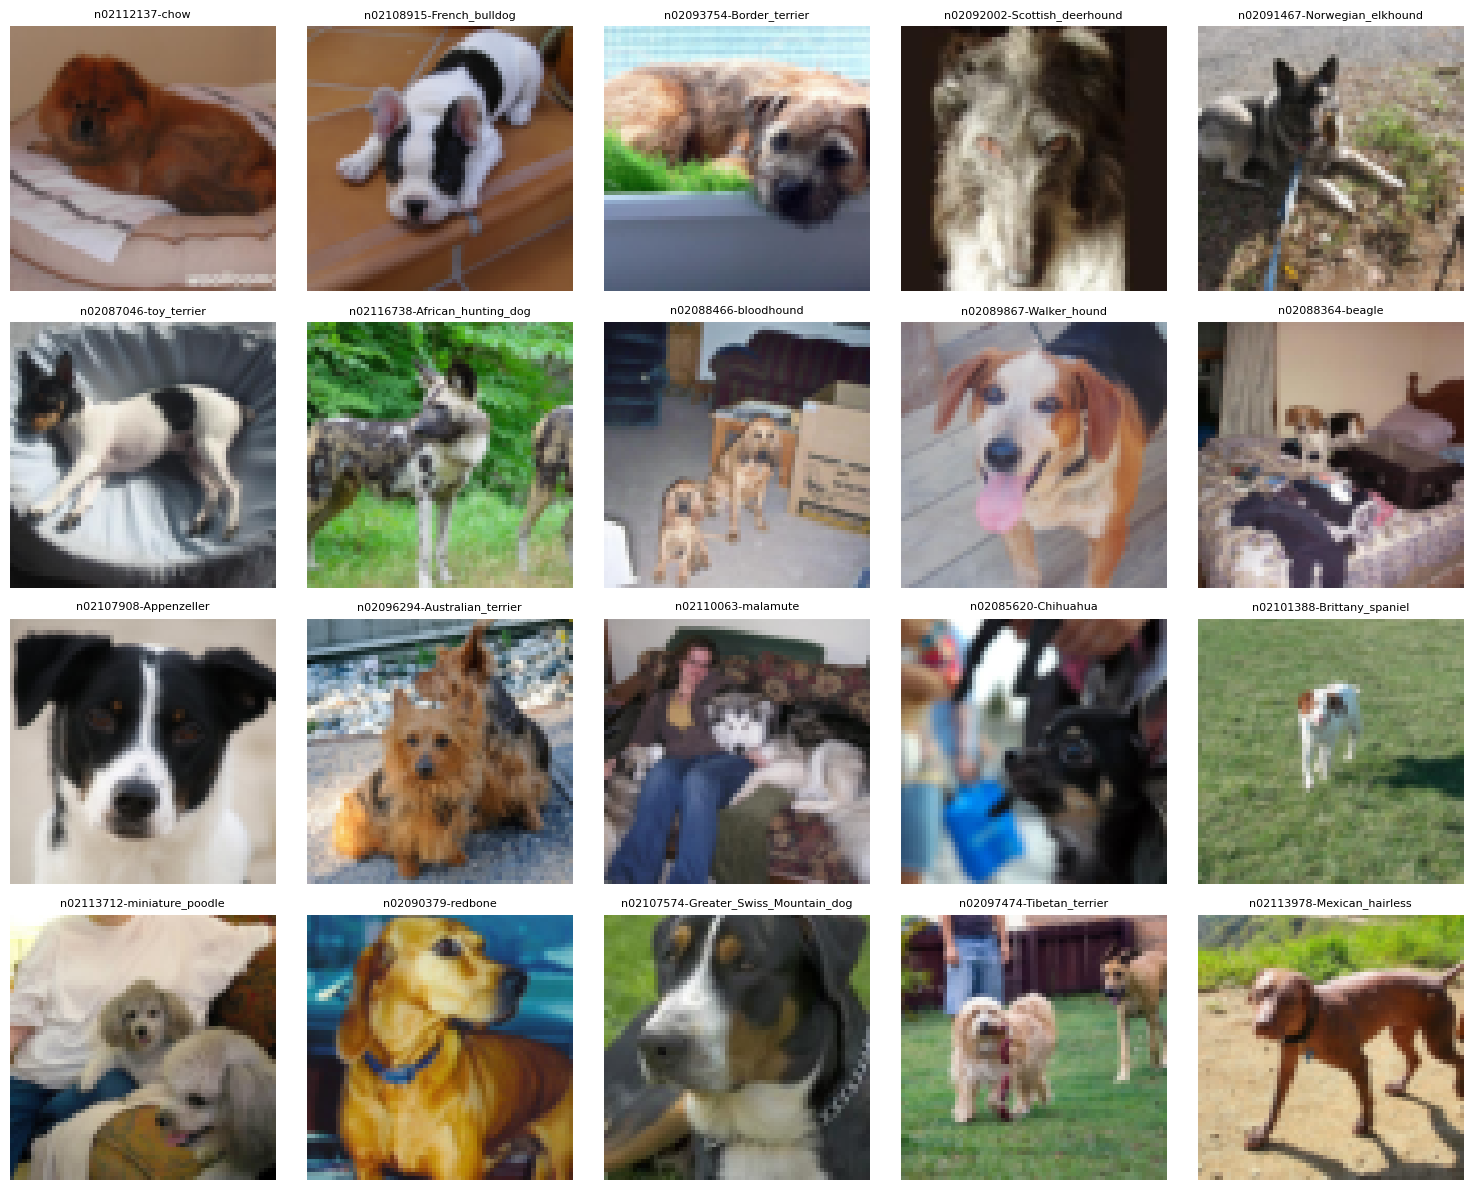

In [ ]:
num_images_to_display = 20

class_indices = {}
for i, (path, label_idx) in enumerate(datasetAdattato.samples):
    if label_idx not in class_indices:
        class_indices[label_idx] = []
    class_indices[label_idx].append(i)

available_labels = list(class_indices.keys())
num_unique_labels = min(num_images_to_display, len(available_labels))
selected_label_indices = random.sample(available_labels, num_unique_labels)

images_to_show_indices = []
for label_idx in selected_label_indices:
    img_idx = random.choice(class_indices[label_idx])
    images_to_show_indices.append(img_idx)

rows = min(4, num_unique_labels)
cols = (num_unique_labels + rows - 1) // rows

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i, data_idx in enumerate(images_to_show_indices):
    img_tensor, label = datasetAdattato[data_idx]

    img = denormalize(img_tensor)
    img_np = img.permute(1, 2, 0).numpy()

    axes[i].imshow(img_np)
    axes[i].set_title(datasetAdattato.classes[label], fontsize=8)
    axes[i].axis('off')

for j in range(num_unique_labels, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Come mostrato, le nuove immagini sono eccessivamente sgranate: le immagini prese casualmente potrebbero non essere significative ma è importante ricordar che nel dataset non ci sono solo foto con esclusivamente cani ma includono ambiente circostante e, tavolta, persone.  
La risoluzione della rete vista a lezione poteva essere adatta per Sprite pixel art ma non per cani.  
Prendiamo in considerazione la UNet originale

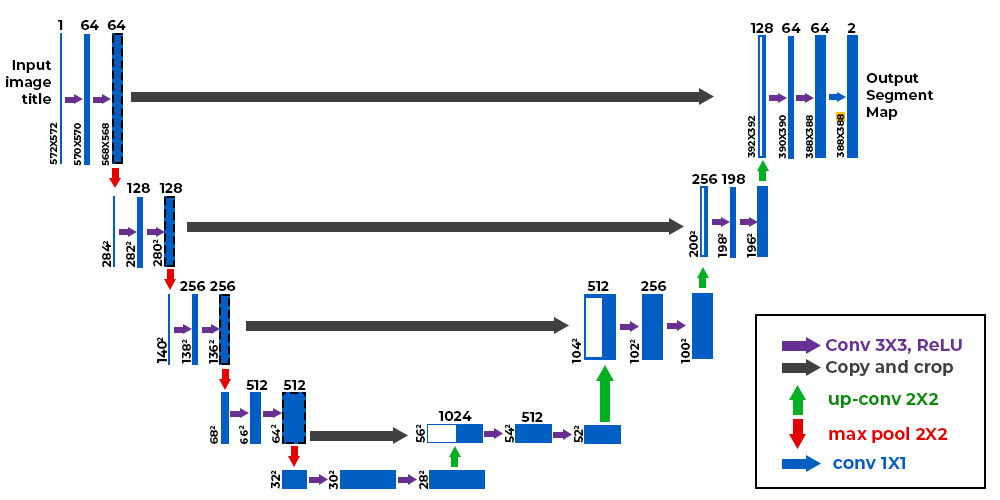

E prendiamo quella vista a lezione

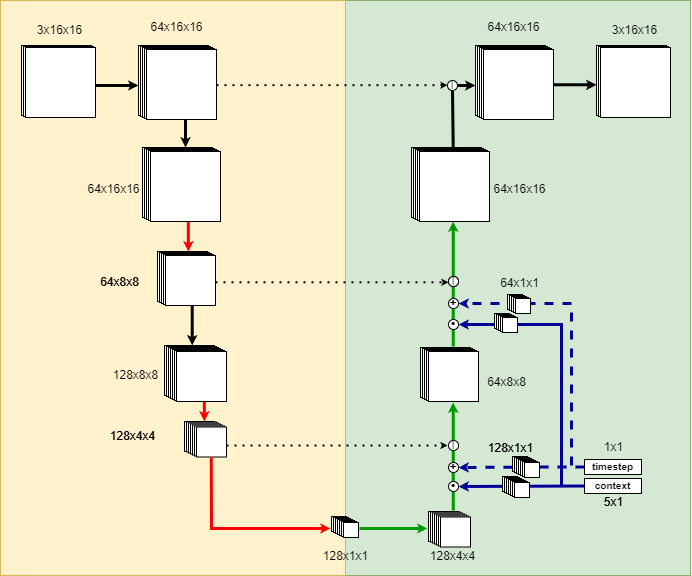

Le immagini d'ingresso sono 16x16 nella rete vista a lezione ma le nostre immagini originali sono 256x256 con il transform iniziale.  
Quindi ora dobbiamo aggiustare la rete e trovare una via di mezzo tra il 16x16 ed il 572 della rete originale.  
L'obbiettivo è quello di aggiustare le dimensioni iniziali cercando di mantenere la struttura

In [ ]:
transform = transforms.Compose([
    transforms.Resize(16),
    transforms.CenterCrop(16),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

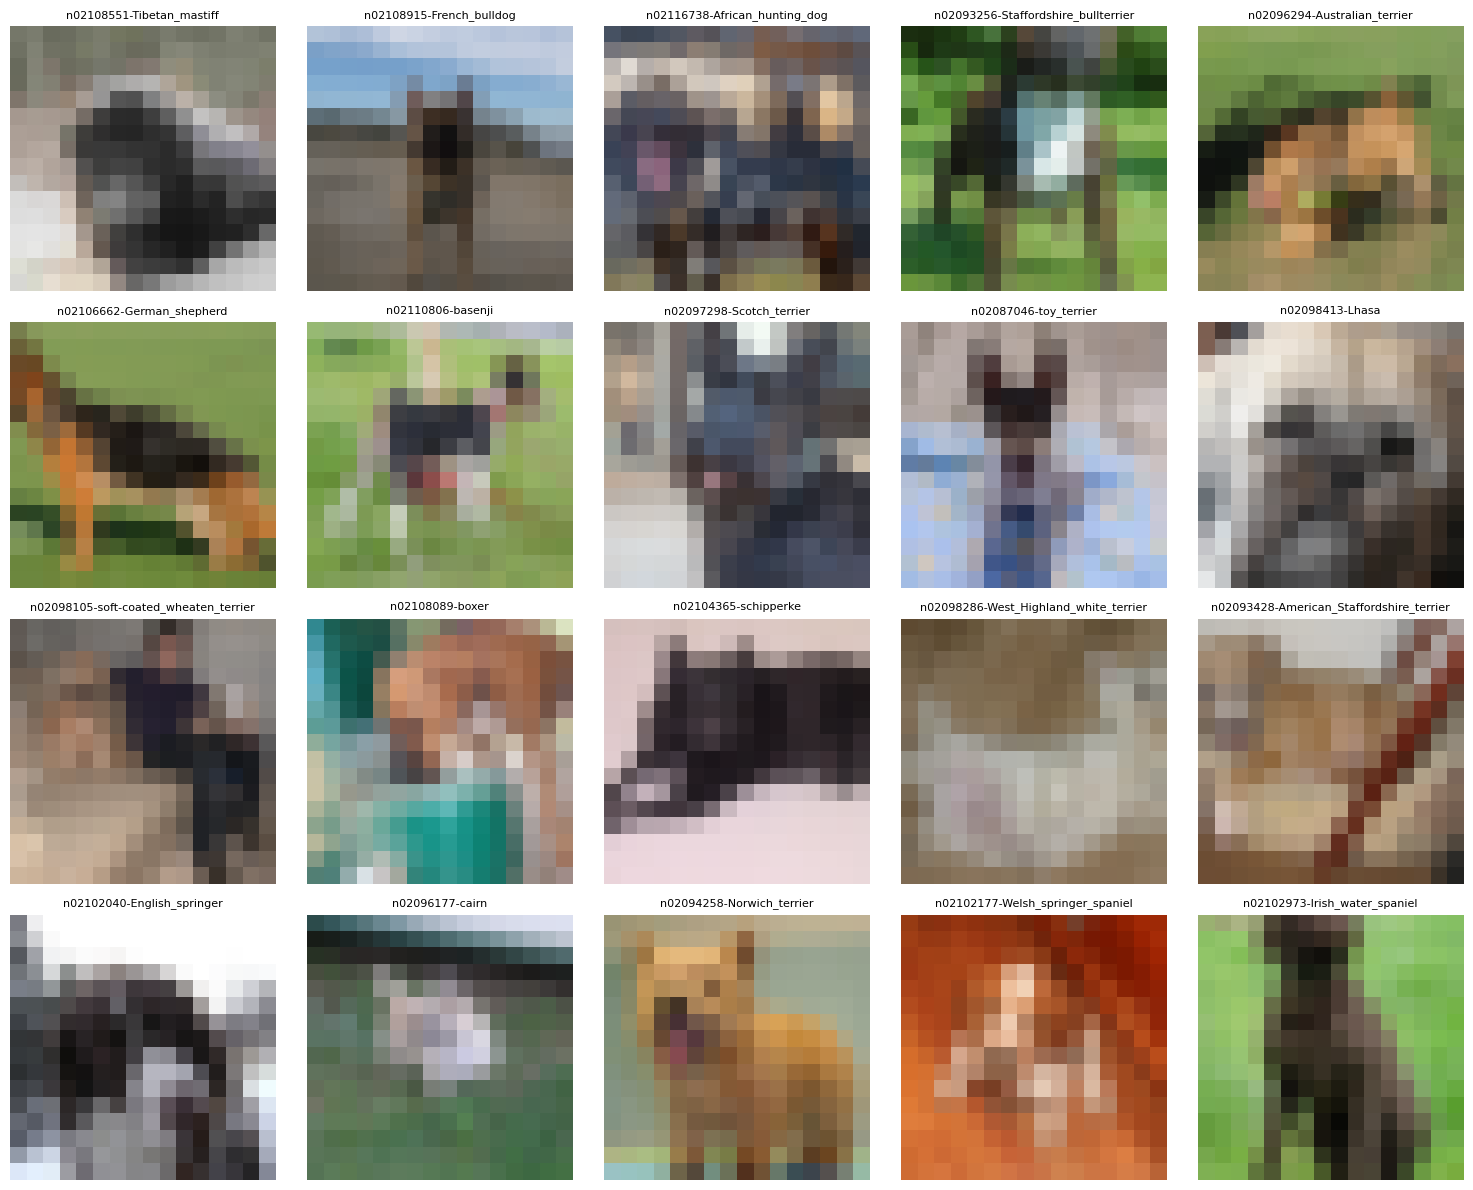

In [ ]:
num_images_to_display = 20

class_indices = {}
for i, (path, label_idx) in enumerate(datasetAdattato.samples):
    if label_idx not in class_indices:
        class_indices[label_idx] = []
    class_indices[label_idx].append(i)

available_labels = list(class_indices.keys())
num_unique_labels = min(num_images_to_display, len(available_labels))
selected_label_indices = random.sample(available_labels, num_unique_labels)

images_to_show_indices = []
for label_idx in selected_label_indices:
    img_idx = random.choice(class_indices[label_idx])
    images_to_show_indices.append(img_idx)

rows = min(4, num_unique_labels)
cols = (num_unique_labels + rows - 1) // rows

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i, data_idx in enumerate(images_to_show_indices):
    img_tensor, label = datasetAdattato[data_idx]

    img = denormalize(img_tensor)
    img_np = img.permute(1, 2, 0).numpy()

    axes[i].imshow(img_np)
    axes[i].set_title(datasetAdattato.classes[label], fontsize=8)
    axes[i].axis('off')

for j in range(num_unique_labels, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### UNet originale

In [ ]:
class Unet(nn.Module):

    def __init__(self, in_channels, n_feat, device):
        super(Unet, self).__init__()
        self.device = device
        self.in_channels = in_channels
        self.n_feat = n_feat

        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        ## Create 2 perchè una sola è non sufficiente
        self.down1 = UnetDown(n_feat, n_feat)
        self.down2 = UnetDown(n_feat, 2 * n_feat)

        # Ora il pooling linee rosse

        self.to_vec = nn.Sequential(
            nn.AvgPool2d(4),
            nn.GELU()
        )

        self.timebed1 = EmbedFC(1, 2 * n_feat)
        self.timebed2 = EmbedFC(1, 1 * n_feat)

        self.up0 = nn.Sequential(
            ## Rimane in 128
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, kernel_size=4, stride=4),

            nn.GroupNorm(8, 2 * n_feat),
            nn.ReLU()
        )

        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        ## Ora le conv finali
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, kernel_size=3, stride=1, padding=1),
            nn.GroupNorm(8, n_feat),
            nn.ReLU(),
            ## Questi kernel & co non fanno cambiare niente
            nn.Conv2d(n_feat, self.in_channels, kernel_size=3, stride=1, padding=1)
        )


    def forward(self, image, timestep):
      init_conv = self.init_conv(image)
      down1 = self.down1(init_conv)
      down2 = self.down2(down1)

      hiddenvec = self.to_vec(down2)
      ## -1 è per batch size
      temb1 = self.timebed1(timestep).view(-1, self.n_feat * 2, 1, 1)
      temb2 = self.timebed2(timestep).view(-1, self.n_feat * 1, 1, 1)

      up0 = self.up0(hiddenvec)
      up1 = self.up1(up0 + temb1, down2)
      up2 = self.up2(up1 + temb2, down1)

      out = self.out(torch.cat((up2, init_conv), dim=1))

      return out


    def train_diffusion(self, dataloader, n_epoch, criterion, optim, lrate, timesteps, ab_t, path_dir):
        self.train()

        train_loss = []
        for ep in tqdm(range(n_epoch)):

            # Vogliamo decadimento del learning rate per migliorare rendimento

            optim.param_groups[0]['lr'] = lrate * (1 - ep / n_epoch)

            for image, _ in dataloader:
              optim.zero_grad()

              image = image.to(self.device)

              ## unsqueeze per assicurare consistenza e non avere errori con la loss
              if image.dim() == 3:
                image = image.unsqueeze(0)

              # perturbazione input con noise random

              noise = torch.randn_like(image) # perché va sommato all'immagine
              t = torch.randint(1, timesteps+1, (image.shape[0], )).to(self.device) # , vuoto come mette 1
              x_pert = perturb_input(image, t, noise, ab_t)

              pred_noise = self(x_pert, t / timesteps) # chiama forward

              loss = criterion(pred_noise, noise)

              loss.backward() # backpropagation
              optim.step() # aggiornamento dei pesi

              train_loss.append(loss.item())


            # save model periodically
            if ep % 4 == 0 or ep == int(n_epoch-1):
                if not os.path.exists(path_dir):
                    os.makedirs(path_dir)

                torch.save(self.state_dict(), path_dir + f"model_{ep}.pth")
                print('saved model at ' + path_dir + f"model_{ep}.pth")

        return train_loss


Ricostruzione dei parametri. Notare che img_dim ora è 16x16, non 64 come prima.

In [ ]:
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
print(device)

# diffusion hyperparameters
NUM_TIMESTEPS = 500
BETA1 = 1e-4
BETA2 = 0.02

# construct DDPM noise schedule (as described in the paper)
b_t = (BETA2 - BETA1) * torch.linspace(0, 1, NUM_TIMESTEPS + 1, device=device) + BETA1
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1

# network hyperparameters
n_feat = 64                 # 64 hidden dimension feature
img_dim = 16                # 16x16 image, QUESTO è QUELLO CAMBIATO NELL'ALTRA RETE
color_dim = 3               # 3 color channels

# training hyperparameters
n_epoch = 32
lrate = 1e-3


cpu


In [ ]:
# construct model

nn_model_og = Unet(in_channels=3, n_feat=n_feat, device=device).to(device)
optim = torch.optim.Adam(nn_model_og.parameters(), lr=lrate)
criterion = nn.MSELoss()

!mkdir -p diffusion


SAVE_DIR = '/content/drive/DiffusionModel/SecondTry/' ## CAMBIARE IL PATH ALL'OCCORRENZA

Nuovo dataset: quello precedente era 64x64 in accordo con l'upscaling voluto rispetto alle foto usate per la UNet originale, per ottenere più dettagli

In [ ]:
transform = transforms.Compose([
    transforms.Resize(16),
    transforms.CenterCrop(16),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

In [ ]:
# Per riprendere training in caso si sia interrotto per limiti di colab
# nn_model_og.load_state_dict(torch.load(f"{os.path.join(SAVE_DIR, "model_28.pth")}", weights_only=False, map_location=device))

In [ ]:
# Train
train_loss = nn_model_og.train_diffusion(datasetAdattato, n_epoch, criterion, optim, lrate, NUM_TIMESTEPS, ab_t, SAVED_DIR)

  3%|▎         | 1/32 [05:02<2:36:11, 302.29s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/DiffusionModel/SecondTrymodel_0.pth


 16%|█▌        | 5/32 [24:58<2:14:41, 299.30s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/DiffusionModel/SecondTrymodel_4.pth


 28%|██▊       | 9/32 [44:52<1:54:25, 298.51s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/DiffusionModel/SecondTrymodel_8.pth


... (8 outputs left out)

 91%|█████████ | 29/32 [2:24:06<14:42, 294.07s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/DiffusionModel/SecondTrymodel_28.pth


100%|██████████| 32/32 [2:38:42<00:00, 297.59s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/DiffusionModel/SecondTrymodel_31.pth


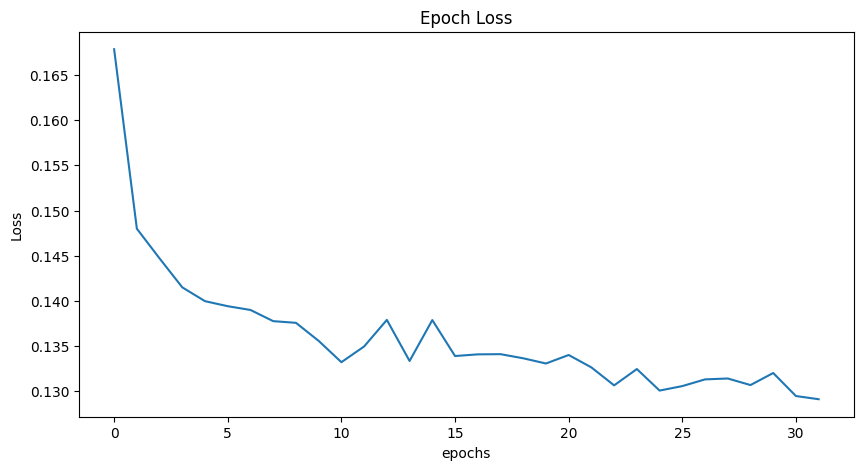

In [ ]:
ep_loss = []

for i in range(0, len(train_loss), len(datasetAdattato)):
    ep_loss.append(sum(train_loss[i:i+len(datasetAdattato)])/len(datasetAdattato))

plt.figure(figsize=(10, 5))
plt.plot(ep_loss)
plt.xlabel("epochs")
plt.ylabel("Loss")
plt.title("Epoch Loss")
plt.show()

In [ ]:
# load in model weights and set to eval mode
nn_model_og.load_state_dict(torch.load(f"{os.path.join(SAVE_DIR, "model_31.pth")}", weights_only=False, map_location=device))
nn_model_og.eval()
print("Loaded in Model")



Loaded in Model


In [ ]:
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(32, img_dim, color_dim, b_t, a_t, ab_t, nn_model_og, save_rate=20)

animation_ddpm = plot_sample(intermediate_ddpm,32,4,SAVE_DIR, "ani_run", None, save=False)


animation_ddpm.save(
    SAVE_DIR + "ddpm_denoising_originalUNet.mp4",
    writer="ffmpeg",
    fps=5,
    dpi=100
)

display(Video(
    SAVE_DIR + "ddpm_denoising_originalUNet.mp4",
    embed=True
))

100%|██████████| 500/500 [02:15<00:00,  3.68it/s]


<Figure size 640x480 with 0 Axes>

## Ultimo approccio
Coinvolge
- Weight Decay
- Uso di 50 epoche con la UNet migliorata
- Uso di dataset 32x32 anziché 64x64 (una via di mezzo)

In [ ]:
transform = transforms.Compose([
    transforms.Resize(32),
    transforms.CenterCrop(32),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

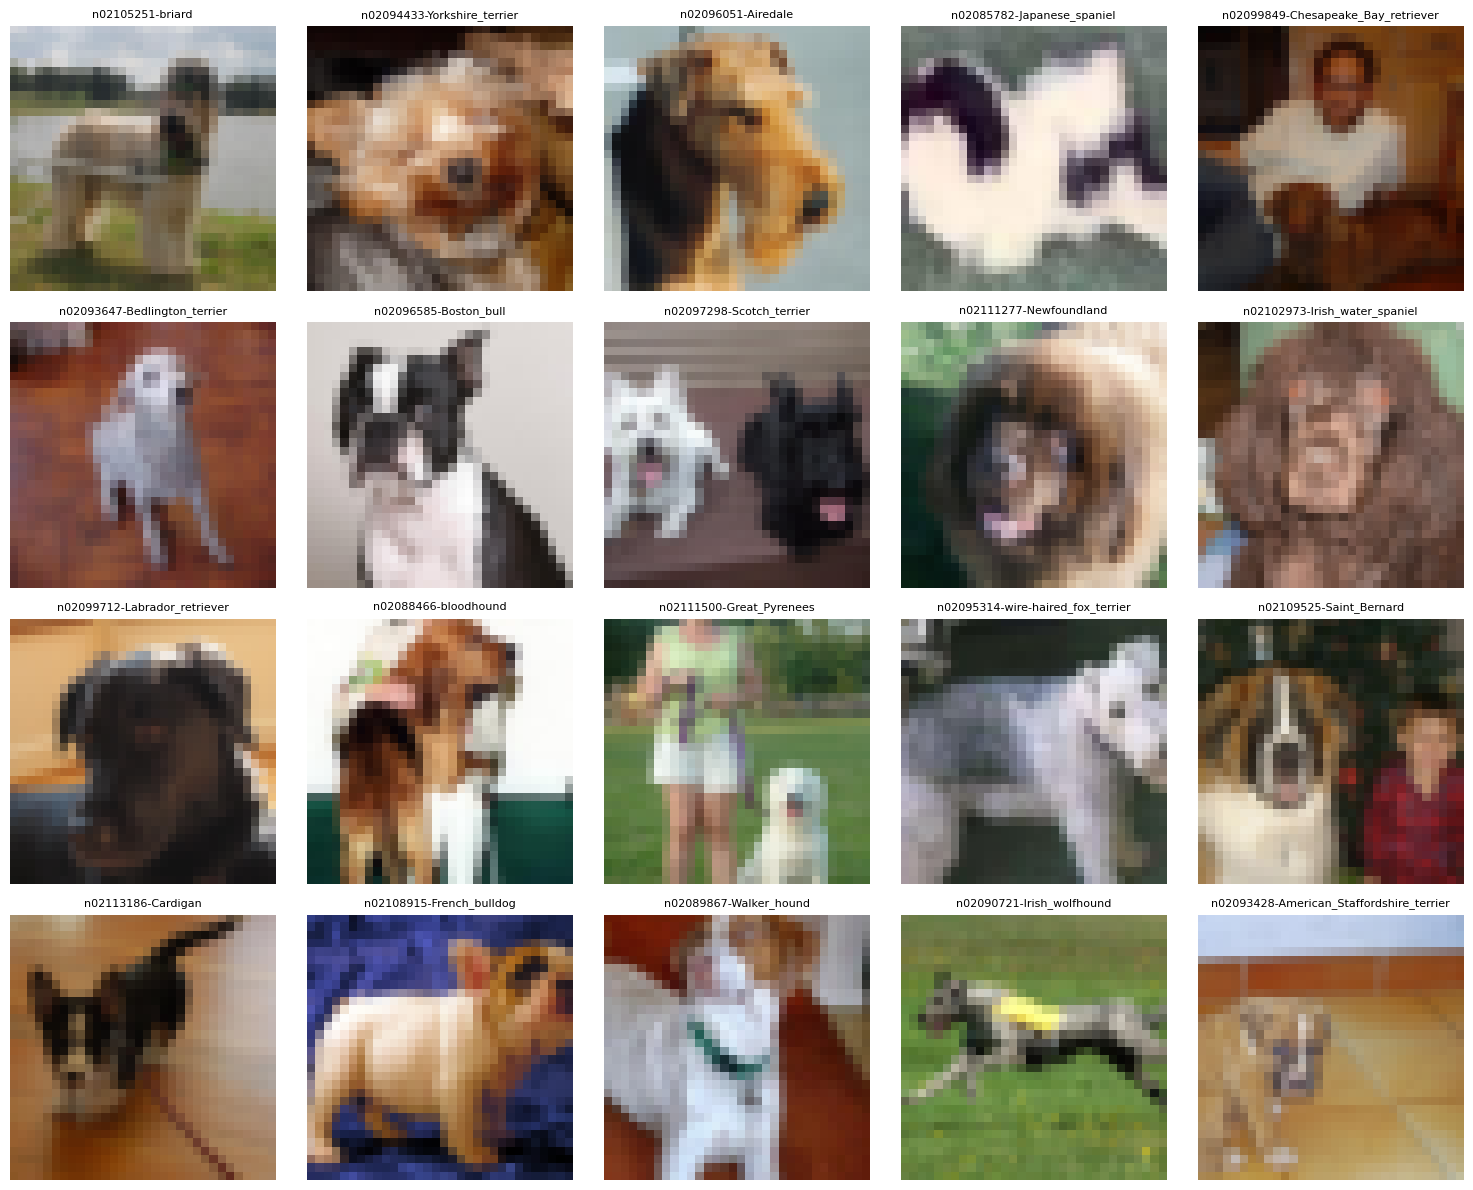

In [ ]:
num_images_to_display = 20

class_indices = {}
for i, (path, label_idx) in enumerate(datasetAdattato.samples):
    if label_idx not in class_indices:
        class_indices[label_idx] = []
    class_indices[label_idx].append(i)

available_labels = list(class_indices.keys())
num_unique_labels = min(num_images_to_display, len(available_labels))
selected_label_indices = random.sample(available_labels, num_unique_labels)

images_to_show_indices = []
for label_idx in selected_label_indices:
    img_idx = random.choice(class_indices[label_idx])
    images_to_show_indices.append(img_idx)

rows = min(4, num_unique_labels)
cols = (num_unique_labels + rows - 1) // rows

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i, data_idx in enumerate(images_to_show_indices):
    img_tensor, label = datasetAdattato[data_idx]

    img = denormalize(img_tensor)
    img_np = img.permute(1, 2, 0).numpy()

    axes[i].imshow(img_np)
    axes[i].set_title(datasetAdattato.classes[label], fontsize=8)
    axes[i].axis('off')

for j in range(num_unique_labels, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Riportiamo qui la rete anche per modificare il salvataggio e caricamento dei dati per adattarlo al weight decay

In [ ]:
class LastImprovedUnet(nn.Module):

    def __init__(self, in_channels, n_feat, device):
        super(LastImprovedUnet, self).__init__()
        self.device = device
        self.in_channels = in_channels
        self.n_feat = n_feat

        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        ## 32 -> 16 -> 8 -> 4
        self.down1 = UnetDown(n_feat, n_feat)
        self.down2 = UnetDown(n_feat, 2 * n_feat)
        self.down3 = UnetDown(2 * n_feat, 2 * n_feat)

        # Ora il pooling linee rosse

        self.to_vec = nn.Sequential(
            nn.AvgPool2d(4),
            nn.GELU()
        )

        self.timebed1 = EmbedFC(1, 2 * n_feat)
        self.timebed2 = EmbedFC(1, 2 * n_feat)
        self.timebed3 = EmbedFC(1, 1 * n_feat)

        self.up0 = nn.Sequential(
            ## Rimane in 128
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, kernel_size=4, stride=4),
            nn.GroupNorm(8, 2 * n_feat),
            nn.ReLU()
        )

        self.up1 = UnetUp(4 * n_feat, 2 * n_feat)
        self.up2 = UnetUp(4 * n_feat, n_feat)
        self.up3 = UnetUp(2 * n_feat, n_feat)

        ## Ora le conv finali
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, kernel_size=3, stride=1, padding=1),
            nn.GroupNorm(8, n_feat),
            nn.ReLU(),
            ## Questi kernel & co non fanno cambiare niente
            nn.Conv2d(n_feat, self.in_channels, kernel_size=3, stride=1, padding=1)
        )


    def forward(self, image, timestep):
      init_conv = self.init_conv(image)
      down1 = self.down1(init_conv)
      down2 = self.down2(down1)
      down3 = self.down3(down2)

      hiddenvec = self.to_vec(down3)
      ## -1 è per batch size
      temb1 = self.timebed1(timestep).view(-1, self.n_feat * 2, 1, 1)
      temb2 = self.timebed2(timestep).view(-1, self.n_feat * 2, 1, 1)
      temb3 = self.timebed3(timestep).view(-1, self.n_feat * 1, 1, 1)

      up0 = self.up0(hiddenvec)
      up1 = self.up1(up0 + temb1, down3)
      up2 = self.up2(up1 + temb2, down2)
      up3 = self.up3(up2 + temb3, down1)

      out = self.out(torch.cat((up3, init_conv), dim=1))

      return out


    def train_diffusion(self, dataloader, n_epoch, criterion, optim, lrate, timesteps, ab_t, path_dir, checkpoint = ""):
        self.train()

        train_loss = []
        epoch_inizio = 0

        if checkpoint and os.path.exists(checkpoint):
          print(f"Si ricomincia da: {checkpoint}")
          epoch_inizio, train_loss = self.load_checkpoint(optim, checkpoint, self.device)

        for ep in tqdm(range(epoch_inizio, n_epoch)):

            # Vogliamo decadimento del learning rate per migliorare rendimento

            optim.param_groups[0]['lr'] = lrate * (1 - ep / n_epoch)

            for image, _ in dataloader:
              optim.zero_grad()

              image = image.to(self.device)

              ## unsqueeze per assicurare consistenza e non avere errori con la loss
              if image.dim() == 3:
                image = image.unsqueeze(0)

              # perturbazione input con noise random

              noise = torch.randn_like(image) # perché va sommato all'immagine
              t = torch.randint(1, timesteps+1, (image.shape[0], )).to(self.device) # , vuoto come mette 1
              x_pert = perturb_input(image, t, noise, ab_t)

              pred_noise = self(x_pert, t / timesteps) # chiama forward

              loss = criterion(pred_noise, noise)

              loss.backward() # backpropagation
              optim.step() # aggiornamento dei pesi

              train_loss.append(loss.item())


            # save model periodically
            if ep % 4 == 0 or ep == int(n_epoch-1):
                if not os.path.exists(path_dir):
                    os.makedirs(path_dir)

                checkpoint_path = path_dir + f"checkpoint_epoch_{ep}.pth"
                self.save_checkpoint(optim, ep, train_loss, checkpoint_path)

                # Also save loss history separately (for easy access)
                loss_path = path_dir + "train_loss.json"
                with open(loss_path, 'w') as f:
                    json.dump(train_loss, f)
                print('saved model at ' + path_dir + f"model_{ep}.pth")

        return train_loss


    def save_checkpoint(self, optimizer, epoch, train_loss, path):
      checkpoint = {
          'epoch': epoch, # Aggiunta anche l'epoch, così da evitare di dover semplicemente leggere il nome e "dedurlo"
          'model_state_dict': self.state_dict(),
          'optimizer_state_dict': optimizer.state_dict(),  # Aggiunta di weight decay
          'train_loss': train_loss, # Aggiunta della loss corrente
      }
      torch.save(checkpoint, path)


    def load_checkpoint(self, optimizer, path, device):
      checkpoint = torch.load(path, map_location=device)

      self.load_state_dict(checkpoint['model_state_dict'])
      optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

      start_epoch = checkpoint['epoch'] + 1 ## L'epoca dopo è quella da cui cominciare
      train_loss = checkpoint['train_loss']

      print(f'Ripreso da epoca {checkpoint["epoch"]} con {len(train_loss)} loss')

      return start_epoch, train_loss

In [ ]:
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
print(device)

# diffusion hyperparameters
NUM_TIMESTEPS = 500
BETA1 = 1e-4
BETA2 = 0.02

# construct DDPM noise schedule (as described in the paper)
b_t = (BETA2 - BETA1) * torch.linspace(0, 1, NUM_TIMESTEPS + 1, device=device) + BETA1
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1

# network hyperparameters
n_feat = 64                 # 64 hidden dimension feature
img_dim = 32                # Questa volta usiamo 32x32, una via di mezzo
color_dim = 3               # 3 color channels

# training hyperparameters
n_epoch = 50
lrate = 5e-4 ## Proviamo anche con un learning rate INIZIALE più basso

cuda:0


In [ ]:
transform = transforms.Compose([
    transforms.Resize(32),  ## ORA USIAMO 32X32
    transforms.CenterCrop(32),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

## Adattato il transform per usare le misure corrette
datasetAdattato = ImageFolder(
    root="images/Images",
    transform=transform
)

Nota: volendo ora usare weight decay, assumendo Colab interrompa l'allenamento, è necessario salvare anche il weight decay. Avendo garanzia che salterà date le epoche, si salva anche al loss per plottarla a fine allenamento

In [ ]:
# construct model

nn_model_last = LastImprovedUnet(in_channels=3, n_feat=n_feat, device=device).to(device)
optim = torch.optim.AdamW(nn_model_last.parameters(), lr=lrate, weight_decay=1e-4)
criterion = nn.MSELoss()

SAVED_DIR = '/content/drive/LastDiffusion_32x32/' ## CAMBIARE IL PATH ALL'OCCORRENZA

5:22 per l'allenamento

In [ ]:
# Se si vuole riprendere, usare questa cella e passarla al train DOPO "SAVED_DIR"
# path_ripresa = SAVED_DIR + "checkpoint_epoch_40.pth"

In [ ]:
# Train
train_loss = nn_model_last.train_diffusion(datasetAdattato, n_epoch, criterion, optim, lrate, NUM_TIMESTEPS, ab_t, SAVED_DIR
                                      # , path_ripresa
                                      )

Si ricomincia da: /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/LastDiffusion_32x32/checkpoint_epoch_40.pth
Resumed from epoch 40 with 843780 loss values


 44%|████▍     | 4/9 [30:06<37:33, 450.67s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/LastDiffusion_32x32/model_44.pth


 89%|████████▉ | 8/9 [59:43<07:25, 445.75s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/LastDiffusion_32x32/model_48.pth


100%|██████████| 9/9 [1:07:14<00:00, 448.24s/it]

saved model at /content/drive/MyDrive/737664 - Progetto Deep & Reti/CharacterRecognition/LastDiffusion_32x32/model_49.pth


Grafico Loss

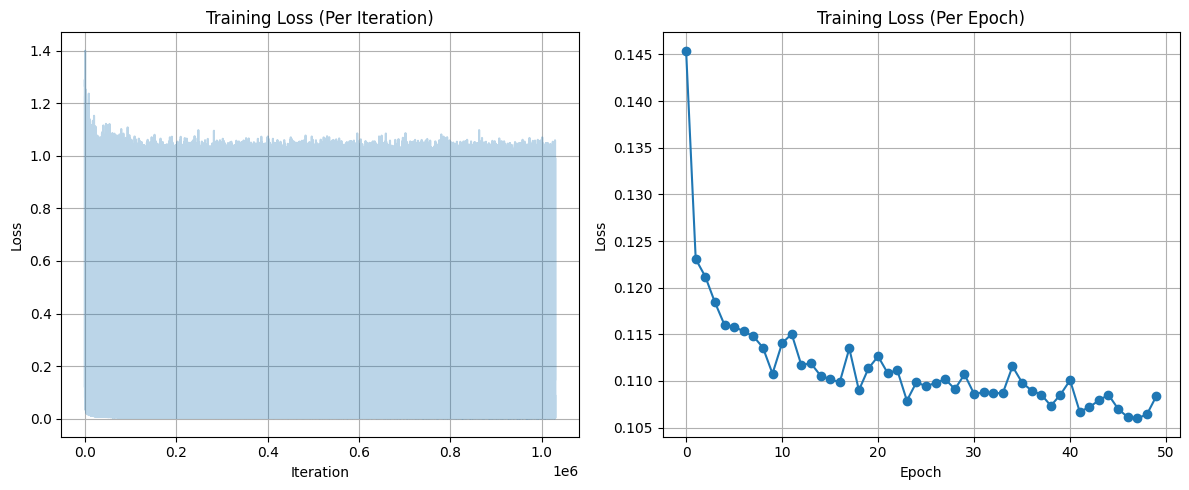

Final epoch loss: 0.1084
Total epochs completed: 50


In [ ]:
## Caricamento della loss
with open(SAVED_DIR + 'train_loss.json', 'r') as f:
    train_loss = json.load(f)

n_batches_per_epoch = len(datasetAdattato)
ep_loss = []

for i in range(0, len(train_loss), n_batches_per_epoch):
    epoch_avg = sum(train_loss[i:i+n_batches_per_epoch]) / n_batches_per_epoch
    ep_loss.append(epoch_avg)

# Plot
plt.figure(figsize=(12, 5))

## Loss per iteration
plt.subplot(1, 2, 1)
plt.plot(train_loss, alpha=0.3)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training Loss (Per Iteration)')
plt.grid(True)

## Loss per epoca
plt.subplot(1, 2, 2)
plt.plot(ep_loss, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss (Per Epoch)')
plt.grid(True)

plt.tight_layout()
plt.savefig(SAVED_DIR + 'loss_curves.png', dpi=150)
plt.show()

print(f"Final epoch loss: {ep_loss[-1]:.4f}")
print(f"Total epochs completed: {len(ep_loss)}")

In [ ]:
# load in model weights and set to eval mode
nn_model_last.load_checkpoint(optim, f"{os.path.join(SAVED_DIR, 'checkpoint_epoch_44.pth')}", device)
nn_model_last.eval()
print("Loaded in Model")

Resumed from epoch 44 with 926100 loss values
Loaded in Model


In [ ]:
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(32, img_dim, color_dim, b_t, a_t, ab_t, nn_model, save_rate=20)

animation_ddpm = plot_sample(intermediate_ddpm,32,4,SAVED_DIR, "ani_run", None, save=False)


animation_ddpm.save(
    SAVED_DIR + "ddpm_denoising_LastUNet_Epoch44
    fps=5,
    dpi=100
)

display(Video(
    SAVED_DIR + "ddpm_denoising_LastUNet.mp4",
    embed=True
))

100%|██████████| 500/500 [00:06<00:00, 80.47it/s]


<Figure size 640x480 with 0 Axes>